## 1. Introduction

In this notebook, we explore ranking and retrieval on two datasets constructed from publicly available data:

- CAIQ: Security questionnaire rows, where the relevant documents are the answers to the same or related controls.
- FiQA: questions and answers from a personal finance forum.

The nDCG@10 metric captures a notion of ranking quality in the top 10 documents output by a ranking algorithm.

$$\mathrm{DCG@10} = \sum_{i=1}^{10} \frac{2^{g_i} - 1}{\log_2(i + 1)}, \qquad \mathrm{nDCG@10} = \frac{\mathrm{DCG@10}}{\mathrm{IDCG@10}}$$

where $g_i$ is the relevance grade of the document at rank $i$ (0 when it is not relevant) and $\mathrm{IDCG@10}$ is the $\mathrm{DCG@10}$ of the best possible ranking, so a perfect ranking scores 1.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import lab

ENCODE_ON_GPU = False  # late interaction: False uses the downloaded token vectors; True encodes them again on your GPU

caiq, fiqa = lab.load("caiq"), lab.load("fiqa")
DATASETS = (caiq, fiqa)

In [2]:
for ds in DATASETS:
    words = [len(lab.tokenize(t)) for t in ds.bodies]
    rel = [sum(g > 0 for g in q.values()) for q in ds.qrels.values()]
    print(f"{ds.name}: {len(ds.ids):,} documents, {len(ds.queries)} questions, "
          f"median document {np.median(words):.0f} words, {np.mean(rel):.1f} relevant documents per question")

caiq: 644 documents, 119 questions, median document 24 words, 9.7 relevant documents per question


fiqa: 57,912 documents, 648 questions, median document 95 words, 2.6 relevant documents per question


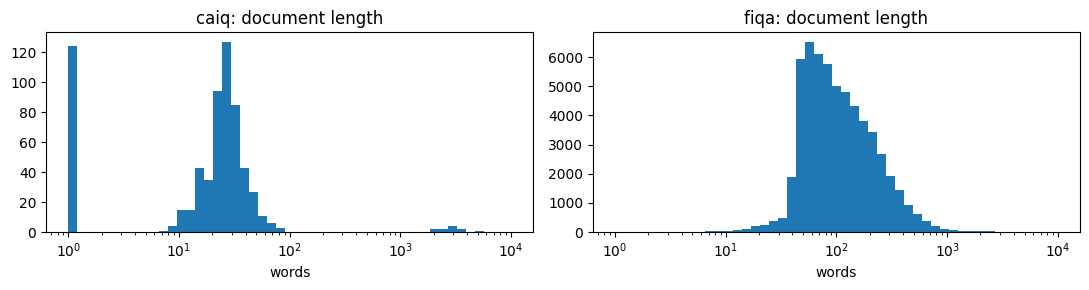

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, ds in zip(axes, DATASETS):
    words = np.array([len(lab.tokenize(t)) for t in ds.bodies])
    ax.hist(words, bins=np.logspace(0, 4, 50))
    ax.set_xscale("log")
    ax.set_title(f"{ds.name}: document length")
    ax.set_xlabel("words")
fig.tight_layout()

In [4]:
for ds in DATASETS:
    qid = next(iter(ds.queries))
    best = max(ds.qrels[qid], key=ds.qrels[qid].get)
    print(f"{ds.name} question: {ds.queries[qid]}")
    print(f"relevant (grade {ds.qrels[qid][best]}): {ds.titles[ds.row[best]]} {ds.bodies[ds.row[best]][:300]}\n")

caiq question: For Fimil: Is a risk-based corrective action plan to remediate audit findings established, documented, approved, communicated, applied, evaluated, and maintained?
relevant (grade 1): Present SpA — A&A-06.1: Is a risk-based corrective action plan to remediate audit findings established, documented, approved, communicated, applied, evaluated, and maintained? Yes. Performed as part of ISO 27001:2013 standard certification.

fiqa question: How to deposit a cheque issued to an associate in my business into my business account?
relevant (grade 1):  Have the check reissued to the proper payee.



## 2. From text to terms

Before we can search for anything, we must turn text into *terms*. We lowercase the text and remove accents (*normalization*), then split it into runs of letters and digits (*tokenization*), dropping punctuation and anything else that is not a Unicode letter or a digit. This process is called *text analysis*. We will add two more steps to it later: stopword removal in section 5 and stemming in section 8.

In [5]:
for s in ("Is data-at-rest encrypted (AES-256)?", "Café naïve ﬁnance: 401(k) or IRA?", "TLS_1.2 vs. TLS-1.3"):
    print(f"{s!r:40} -> {lab.tokenize(s)}")

'Is data-at-rest encrypted (AES-256)?'   -> ['is', 'data', 'at', 'rest', 'encrypted', 'aes', '256']
'Café naïve ﬁnance: 401(k) or IRA?'      -> ['cafe', 'naive', 'finance', '401', 'k', 'or', 'ira']
'TLS_1.2 vs. TLS-1.3'                    -> ['tls', '1', '2', 'vs', 'tls', '1', '3']


## 3. An inverted index

To efficiently match query terms to document terms, we index all document terms into an *inverted index*, which maps each term to the list of documents (*postings*) containing it. The resulting list is called a *posting list*. Our index is a *positional index*, which means that each posting additionally keeps the position of each occurrence of the term within the document. This enables efficient matching of *phrases* (sequences of terms).

In [6]:
ix = lab.index(caiq.bodies)
docs, tf = ix.postings("encryption")
print(f"encryption: in {len(docs)} of {ix.n} documents; postings (document, count): {list(zip(docs[:5].tolist(), tf[:5].astype(int).tolist()))} …")
keys = ix.occurrences("encryption")[:5]
print(f"occurrences (document, position): {[(int(k // lab.STRIDE), int(k % lab.STRIDE)) for k in keys]} …")

a, b = ix.postings("encryption")[0], ix.postings("keys")[0]
print(f"encryption AND keys: {len(np.intersect1d(a, b))} documents; encryption OR keys: {len(np.union1d(a, b))}")
docs, tf = ix.where([(0, "encryption"), (1, "keys")])  # "keys" one position after "encryption"
print(f'"encryption keys": {len(docs)} documents, {int(tf.sum())} times')


def sizes(name, analyzer):
    """The index's vocabulary (distinct terms) and occurrences in each dataset."""
    print(f"{name:18s}" + "".join(f"  {ds.name}: {len(ix.vocab):6,d} terms {int(ix.lengths.sum()):10,d} occurrences"
                                    for ds in DATASETS for ix in [lab.index(ds.bodies, analyzer)]))

print()
sizes("tokens", lab.TOKENS)

encryption: in 53 of 644 documents; postings (document, count): [(22, 1), (159, 1), (162, 1), (163, 1), (165, 2)] …
occurrences (document, position): [(22, 22), (159, 24), (162, 5), (163, 12), (165, 3)] …
encryption AND keys: 10 documents; encryption OR keys: 55
"encryption keys": 8 documents, 10 times



tokens              caiq:  1,831 terms     47,491 occurrences  fiqa: 77,486 terms  8,271,209 occurrences


## 4. Matching words

We now have the building blocks for the simplest ranking algorithm: count how many of the question's terms each document contains, the *term overlap*.

$$\mathrm{overlap}(q, d) = \lvert T(q) \cap T(d) \rvert$$

where $T(q)$ and $T(d)$ are the sets of distinct terms in the question $q$ and the document $d$.

                      caiq               fiqa         
matching words       0.016              0.079         


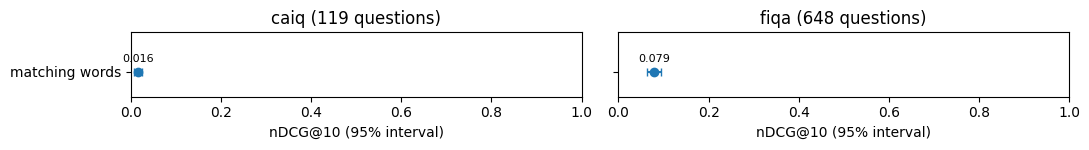

In [7]:
MATCH = {ds.name: lab.matching(ds, ds.bodies) for ds in DATASETS}  # how many of the question's words each document has
runs = {ds.name: {"matching words": lab.evaluate(ds, MATCH[ds.name])} for ds in DATASETS}
lab.plot_ladder(runs);

In [8]:
lab.show(caiq, caiq.qids[0], {"matching words": MATCH["caiq"]})

q:fimil:A&A-06.1: For Fimil: Is a risk-based corrective action plan to remediate audit findings established, documented, approved, communicated, applied, evaluated, and maintained?

matching words  nDCG@10 0.000
  1. [.] misc:007       Untitled Yes. Yes. Audit logs stored in PostgreSQL with database-level access controls. Ad…
  2. [.] misc:001       Untitled Yes. Yes. The organization maintains incident response procedures as part of Info…
  3. [.] misc:009       Untitled NA. Cloud-hosted on DigitalOcean. Physical datacenter asset tracking is the cloud…
  4. [.] misc:000       Untitled Partial. People Security Policy defines endpoint security requirements. Technical…
  5. [.] misc:002       Untitled Yes. Incident Response Plan defines customer notification procedures for data bre…



## 5. Stopwords

The above algorithm has the following problem: very common terms such as "the", "be", "to" and "of" occur in almost every document, so they add to the overlap of nearly every document while carrying almost no information. These terms are called *stopwords*. We add stopword removal to the text analysis, so that they no longer count.

stopwords: ['are', 'and', 'are']


without stopwords   caiq:  1,777 terms     42,407 occurrences  fiqa: 77,422 terms  4,938,427 occurrences


fiqa: nDCG@10 0.079 before, 0.106 after; better 104, worse 53 of 648 questions; fixed 5, broken 0 (from below 0.3 to above 0.7, or back)

691: How to categorize credit card payments?

matching words  nDCG@10 0.000
  1. [.] 2064           8 hard inquiries spread over two years is not a negative factor, with a score of 750. Real…
  2. [.] 5203           I have credit card debt of about $5000 That's the answer right there. You told us the 401(…
  3. [.] 5953           The answer depends on how much you spend every month. The DTI is calculated using the mini…
  4. [.] 7428           &gt; How do I guarantee that people are held liable for damages and/or trying to steal the…
  5. [.] 11936          "What you have is usually called a pre-paid credit card. You pay some money (Indian Rupees…

+ stopwords  nDCG@10 1.000
  1. [1] 395912         "Using the Transfer category is the best place to put these categories, as that accurately…
  2. [.] 2064           8 hard inquiries spread over two years

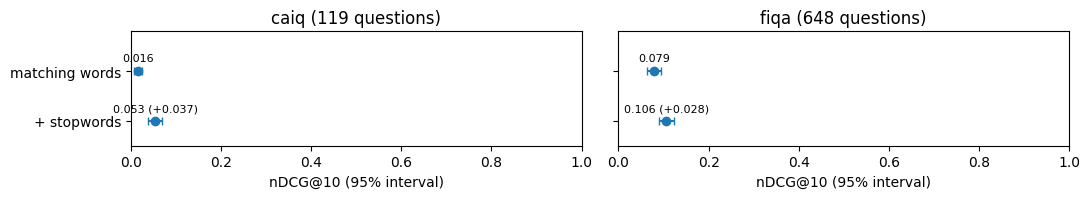

In [9]:
STOP = lab.Analyzer(stopwords=True)  # tokens without stopwords
print("stopwords:", [w for w in lab.tokenize("Are encryption keys rotated and are encrypted backups stored offsite?") if w in lab.STOPWORDS])
sizes("without stopwords", STOP)

MATCH_STOP = {ds.name: lab.matching(ds, ds.bodies, STOP) for ds in DATASETS}
for ds in DATASETS:
    runs[ds.name]["+ stopwords"] = lab.evaluate(ds, MATCH_STOP[ds.name])
example = lab.example(fiqa, runs["fiqa"]["matching words"], runs["fiqa"]["+ stopwords"])
lab.show(fiqa, example, {"matching words": MATCH["fiqa"], "+ stopwords": MATCH_STOP["fiqa"]})
lab.plot_ladder(runs);

## 6. TF-IDF

Removing stopwords helps, but every remaining term still counts the same: a match on "data" counts as much as a match on "pseudonymization".

Therefore, in addition to ranking in proportion to *term frequency* (how often a term occurs in a document), we want to give less weight to common terms and more weight to rare terms. This is captured by *inverse document frequency*, which is roughly log(N / df), where N is the number of documents and df the number of documents that contain the term.

$$\mathrm{idf}(t) = \ln\left(1 + \frac{N - \mathrm{df}(t) + 0.5}{\mathrm{df}(t) + 0.5}\right) \approx \ln \frac{N}{\mathrm{df}(t)}$$

where $N$ is the number of documents and $\mathrm{df}(t)$ the number of documents that contain the term $t$. The exact form, which we use, never goes below zero.

Combining term frequency and inverse document frequency gives us the TF-IDF ranking algorithm:

$$\mathrm{tfidf}(q, d) = \sum_{t \in T(q)} \mathrm{tf}(t, d) \cdot \mathrm{idf}(t)$$

where $\mathrm{tf}(t, d)$ is how many times the term $t$ occurs in the document $d$.

caiq: nDCG@10 0.053 before, 0.030 after; better 10, worse 44 of 119 questions; fixed 0, broken 0 (from below 0.3 to above 0.7, or back)

q:present:HRS-11.2: For Present SpA: Are regular security awareness training updates provided?

+ stopwords  nDCG@10 0.369
  1. [.] misc:007       Untitled Yes. Yes. Audit logs stored in PostgreSQL with database-level access controls. Ad…
  2. [1] present:HRS-11.1 Present SpA — HRS-11.1: Is a security awareness training program for all employees of the …
  3. [.] misc:003       Untitled NA. Yes. Automated quarterly access reviews via Fimil-Ops endpoints. API token au…
  4. [.] misc:005       Untitled Yes. Operator role is the highest privilege level (100). Impersonation limited to…
  5. [.] misc:006       Untitled Yes. Change Management Policy defines Emergency change type with expedited approv…

tf-idf  nDCG@10 0.145
  1. [.] misc:008       Untitled NA. Cloud-hosted on DigitalOcean. Physical hardware relocation is the cloud provi…
  2. [.] misc:005  

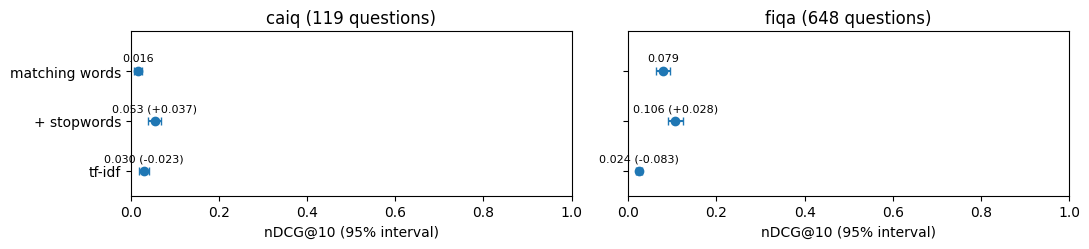

In [10]:
TFIDF = {ds.name: lab.tfidf(ds, ds.bodies, STOP) for ds in DATASETS}
for ds in DATASETS:
    runs[ds.name]["tf-idf"] = lab.evaluate(ds, TFIDF[ds.name])
example = lab.example(caiq, runs["caiq"]["+ stopwords"], runs["caiq"]["tf-idf"], broken=True)
lab.show(caiq, example, {"+ stopwords": MATCH_STOP["caiq"], "tf-idf": TFIDF["caiq"]})
lab.plot_ladder(runs);

In [11]:
for d in lab.top(caiq, example, TFIDF["caiq"], 3):
    terms = STOP.terms(caiq.bodies[caiq.row[d]])[0]
    common = sorted(set(terms), key=terms.count, reverse=True)[:5]
    print(f"{d}: {len(terms):,} terms; most frequent: " + ", ".join(f"{t} ×{terms.count(t)}" for t in common))

misc:008: 2,468 terms; most frequent: production ×571, environments ×285, separated ×285, non ×285, spa ×285
misc:005: 2,985 terms; most frequent: trained ×251, least ×250, once ×250, personnel ×250, provided ×250
misc:006: 2,981 terms; most frequent: security ×229, reviewed ×228, automated ×228, audit ×228, tools ×227


## 7. BM25

TF-IDF performed worse than plain term overlap. It has two problems. The score grows linearly with term frequency, so the tenth occurrence of a term adds as much as the first. And long documents contain more terms and more occurrences, so they match more of everything. BM25 fixes both:

- Term frequency saturation: each extra occurrence adds less than the one before, and the contribution approaches a limit. The parameter **k1** sets how fast it saturates.

- Document length normalization: a document's term frequency is adjusted relative to what is expected for an average document of the same length. The parameter **b** controls the strength of this effect (0 = not at all, 1 = fully).

BM25 is the standard lexical ranking function used in many production retrieval systems.

$$\mathrm{BM25}(q, d) = \sum_{t \in T(q)} \mathrm{idf}(t) \cdot \frac{\mathrm{tf}(t, d)\,(k_1 + 1)}{\mathrm{tf}(t, d) + k_1 \left(1 - b + b\,\frac{\lvert d \rvert}{\mathrm{avgdl}}\right)}$$

where $\lvert d \rvert$ is the document's length in terms, $\mathrm{avgdl}$ the average length, and by default $k_1 = 1.2$ and $b = 0.75$. As $\mathrm{tf}(t, d)$ grows, the fraction approaches $k_1 + 1$.

caiq: nDCG@10 0.030 before, 0.224 after; better 98, worse 0 of 119 questions; fixed 0, broken 0 (from below 0.3 to above 0.7, or back)

q:fimil:TVM-10.1: For Fimil: Are metrics for vulnerability identification and remediation established?

tf-idf  nDCG@10 0.000
  1. [.] misc:003       Untitled NA. Yes. Automated quarterly access reviews via Fimil-Ops endpoints. API token au…
  2. [.] misc:001       Untitled Yes. Yes. The organization maintains incident response procedures as part of Info…
  3. [.] misc:002       Untitled Yes. Incident Response Plan defines customer notification procedures for data bre…
  4. [.] misc:004       Untitled Yes. During annual ISO 27001 re- certification process or based on major changes …
  5. [.] misc:007       Untitled Yes. Yes. Audit logs stored in PostgreSQL with database-level access controls. Ad…

bm25  nDCG@10 0.640
  1. [1] present:TVM-10.1 Present SpA — TVM-10.1: Are metrics for vulnerability identification and remediation estab…
  2. [.] present:SE

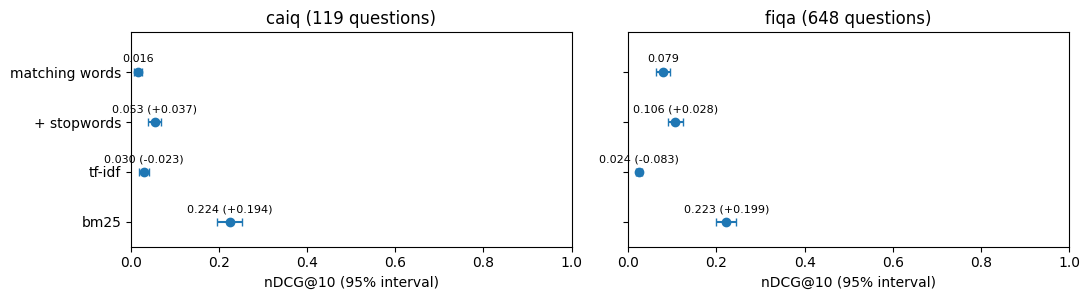

In [12]:
BM25 = {ds.name: lab.bm25(ds, ds.bodies, analyzer=STOP) for ds in DATASETS}
for ds in DATASETS:
    runs[ds.name]["bm25"] = lab.evaluate(ds, BM25[ds.name])
example = lab.example(caiq, runs["caiq"]["tf-idf"], runs["caiq"]["bm25"])
lab.show(caiq, example, {"tf-idf": TFIDF["caiq"], "bm25": BM25["caiq"]})
lab.plot_ladder(runs);

caiq       b = 0  b = 0.25   b = 0.5  b = 0.75     b = 1
k1 0.6     0.049     0.188     0.216     0.233     0.243
k1 1.2     0.043     0.182     0.208     0.224     0.243
k1 2.0     0.042     0.165     0.195     0.217     0.238
fiqa       b = 0  b = 0.25   b = 0.5  b = 0.75     b = 1
k1 0.6     0.166     0.215     0.221     0.225     0.217
k1 1.2     0.165     0.214     0.221     0.223     0.201
k1 2.0     0.152     0.204     0.218     0.210     0.186


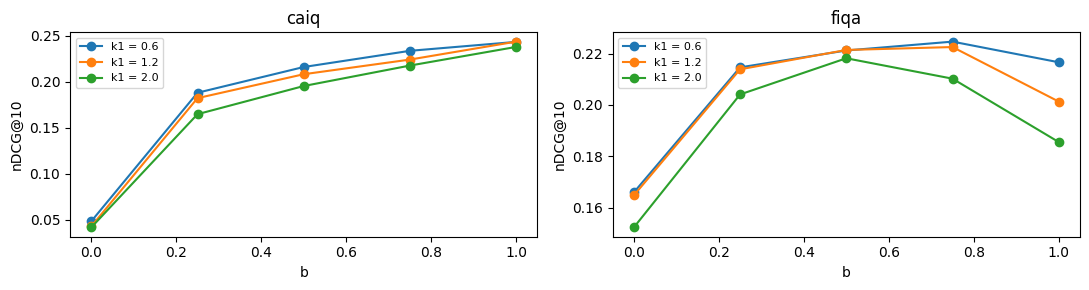

In [13]:
K1, B = (0.6, 1.2, 2.0), (0, 0.25, 0.5, 0.75, 1)
grid = {(ds.name, k1, b): np.mean(list(lab.evaluate(ds, lab.bm25(ds, ds.bodies, k1, b, analyzer=STOP)).values()))
        for ds in DATASETS for k1 in K1 for b in B}
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, ds in zip(axes, DATASETS):
    for k1 in K1:
        ax.plot(B, [grid[ds.name, k1, b] for b in B], marker="o", label=f"k1 = {k1}")
    ax.set_title(ds.name)
    ax.set_xlabel("b")
    ax.set_ylabel("nDCG@10")
    ax.legend(fontsize=8)
fig.tight_layout()
for ds in DATASETS:
    print(f"{ds.name:6s}" + "".join(f"{'b = ' + str(b):>10s}" for b in B))
    for k1 in K1:
        print(f"k1 {k1:<3}" + "".join(f"{grid[ds.name, k1, b]:10.3f}" for b in B))

## 8. Stemming

So far, each term had to match exactly, so a question about "rotating encryption keys" does not match "key rotation".

A *stemmer* reduces each term to a common stem: "rotating", "rotation" and "rotated" all become "rotat", and "encryption" and "encrypted" both become "encrypt". We add the **Snowball stemmer** to the text analysis pipeline.

Stemming raises *recall* (more relevant documents match) at some cost in *precision*, since unrelated words can share a stem. This is generally desirable, but too aggressive stemming algorithms can hurt precision too much. The Snowball stemmer is a good starting point, with support for many languages.

terms: ['encrypt', 'key', 'rotat', 'encrypt', 'backup', 'store', 'offsit']


stemmed             caiq:  1,290 terms     42,407 occurrences  fiqa: 56,918 terms  4,938,427 occurrences


caiq: nDCG@10 0.224 before, 0.259 after; better 61, worse 41 of 119 questions; fixed 0, broken 0 (from below 0.3 to above 0.7, or back)

q:octopus:IVS-12.1: For Octopus Deploy: Are policies and procedures established and mechanisms configured and implemented to protect the wireless network environment perimeter and to restrict unauthorized wireless traffic?

bm25  nDCG@10 0.000
  1. [.] fimil:IVS-03.3 Fimil — IVS-03.3: Are communications between environments restricted to authenticated conn…
  2. [.] misc:005       Untitled Yes. Operator role is the highest privilege level (100). Impersonation limited to…
  3. [.] misc:009       Untitled NA. Cloud-hosted on DigitalOcean. Physical datacenter asset tracking is the cloud…
  4. [.] misc:006       Untitled Yes. Change Management Policy defines Emergency change type with expedited approv…
  5. [.] fimil:IVS-01.1 Fimil — IVS-01.1: Are infrastructure and virtualization security policies and procedures e…

+ stemming  nDCG@10 0.415
  1. [.] mis

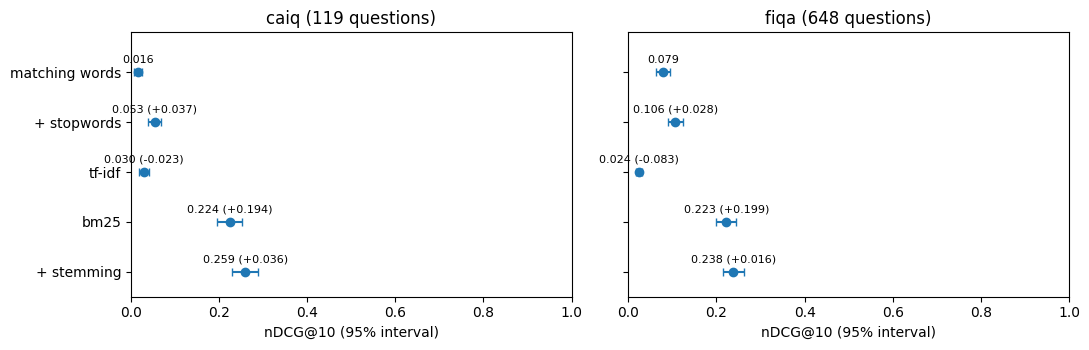

In [14]:
STEM = lab.Analyzer(stopwords=True, stemming=True)  # ... and each term reduced to its stem
print("terms:", STEM.terms("Are encryption keys rotated and are encrypted backups stored offsite?")[0])
sizes("stemmed", STEM)

STEMMED = {ds.name: lab.bm25(ds, ds.bodies, analyzer=STEM) for ds in DATASETS}
for ds in DATASETS:
    runs[ds.name]["+ stemming"] = lab.evaluate(ds, STEMMED[ds.name])
example = lab.example(caiq, runs["caiq"]["bm25"], runs["caiq"]["+ stemming"])
lab.show(caiq, example, {"bm25": BM25["caiq"], "+ stemming": STEMMED["caiq"]})
lab.plot_ladder(runs);

## 9. Multi-field BM25

Real documents are structured in multiple fields: usually at least a title and a body of text. A match in the title generally matters more than a match somewhere in a long body. Different fields also have different statistics and semantic meaning, so we might want to compute BM25 for each field separately and weight them differently.

We add a second BM25 score for the title. For CAIQ, we found that combining the IDF statistics for the two fields resulted in better ranking quality, but on other datasets the opposite could be true. FiQA has very few titles. Always tune your ranking function on a representative sample of data for your use case.

$$s(q, d) = \mathrm{BM25}(q, \mathrm{body}_d) + \mathrm{BM25}(q, \mathrm{title}_d)$$

where $\mathrm{body}_d$ and $\mathrm{title}_d$ are the document's two fields, and both scores use one idf, with $\mathrm{df}(t)$ counted over title and body together.

caiq: body + title, IDF per field 0.513, IDF over title and body together 0.549


fiqa: body + title, IDF per field 0.238, IDF over title and body together 0.238
                      caiq               fiqa         
matching words       0.016              0.079         
+ stopwords          0.053 (+0.037)     0.106 (+0.028)
tf-idf               0.030 (-0.023)     0.024 (-0.083)
bm25                 0.224 (+0.194)     0.223 (+0.199)
+ stemming           0.259 (+0.036)     0.238 (+0.016)
+ title              0.549 (+0.290)     0.238 (+0.000)


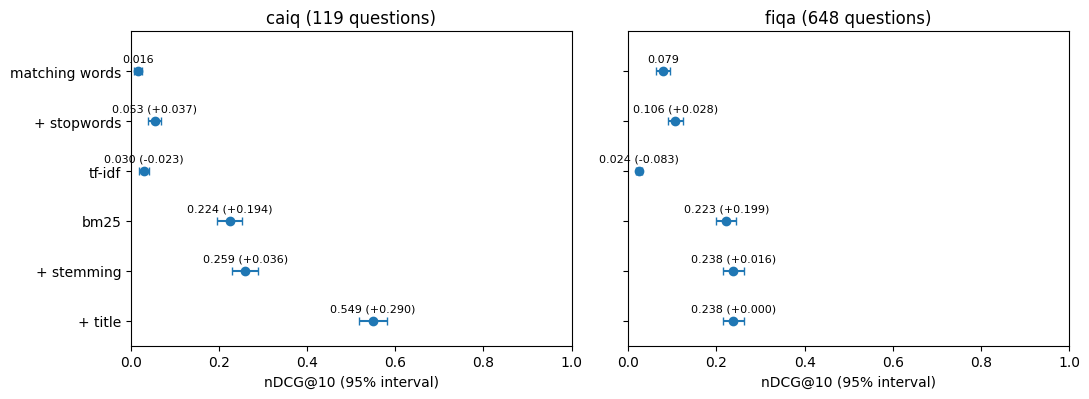

In [15]:
own = {ds.name: lab.bm25(ds, ds.titles, analyzer=STEM) for ds in DATASETS}  # the title's IDF from the titles alone
BODY = {ds.name: lab.bm25(ds, ds.bodies, idf_texts=ds.title_body, analyzer=STEM) for ds in DATASETS}  # from here on, every
TITLE = {ds.name: lab.bm25(ds, ds.titles, idf_texts=ds.title_body, analyzer=STEM) for ds in DATASETS}  # field's IDF is the same
for ds in DATASETS:
    per_field = lab.evaluate(ds, STEMMED[ds.name] + own[ds.name])
    shared = lab.evaluate(ds, BODY[ds.name] + TITLE[ds.name])
    print(f"{ds.name}: body + title, IDF per field {np.mean(list(per_field.values())):.3f}, "
          f"IDF over title and body together {np.mean(list(shared.values())):.3f}")
    runs[ds.name]["+ title"] = shared
del own
lab.plot_ladder(runs);

In [16]:
example = lab.example(caiq, runs["caiq"]["+ stemming"], runs["caiq"]["+ title"])
lab.show(caiq, example, {"+ stemming": STEMMED["caiq"], "+ title": BODY["caiq"] + TITLE["caiq"]})

caiq: nDCG@10 0.259 before, 0.549 after; better 117, worse 1 of 119 questions; fixed 6, broken 0 (from below 0.3 to above 0.7, or back)

q:realigned:BCR-11.1: For Realigned Technologies: Do you have technical capabilities to enforce tenant data retention policies?

+ stemming  nDCG@10 0.130
  1. [.] misc:009       Untitled NA. Cloud-hosted on DigitalOcean. Physical datacenter asset tracking is the cloud…
  2. [.] misc:010       Untitled NA. For the purpose of the questionnaire the question is not applicable, since wi…
  3. [.] misc:004       Untitled Yes. During annual ISO 27001 re- certification process or based on major changes …
  4. [1] fimil:DSP-16.1 Fimil — DSP-16.1: Do data retention, archiving, and deletion practices follow business req…
  5. [.] fimil:HRS-05.1 Fimil — HRS-05.1: Are return procedures of organizationally-owned assets by terminated emp…

+ title  nDCG@10 0.775
  1. [1] octopus:BCR-11.1 Octopus Deploy — BCR-11.1: Do you have technical capabilities to enforce tenan

## 10. Synonyms

Stemming creates an equivalence class of slightly different forms of the same word. In the same way, we would like to equate different ways of writing the same concept, like "single sign on" and "SSO". A *synonym list* can close this *vocabulary mismatch* by *query expansion*: at query time, each synonym phrase in the search query text scores as its best-matching alternative in each document.

$$\mathrm{score}_g(d) = \max_{a \in g} \mathrm{BM25}(a, d)$$

where $g$ is a synonym group that occurs in the question, $a$ runs over its phrases (the question's own wording among them), and $\mathrm{BM25}(a, d)$ scores the phrase $a$ in the document $d$.

With current generation vector search systems, it rarely makes sense to use generic off-the-shelf synonym databases, but domain-specific synonym lists tailored to specific query patterns and data, derived from real users interacting with your system, can make a significant difference.

In [17]:
ANALYZER = lab.Analyzer(stopwords=True, stemming=True, synonyms=lab.synonyms())  # every lexical step from here on
print(f"{len(ANALYZER.groups)} synonym groups, e.g.")
for group in ANALYZER.groups[:6]:
    print("  " + " | ".join(" ".join(p) for p in group))
for ds in DATASETS:
    found = sum(bool(ANALYZER.query(ds.queries[q])[1]) for q in ds.qids)
    print(f"{ds.name}: {found} of {len(ds.qids)} questions contain a synonym phrase")
words, groups = ANALYZER.query(caiq.queries[caiq.qids[0]])
print(f"\n{caiq.queries[caiq.qids[0]]}\n  words: {words}\n  phrases: {groups}")

53 synonym groups, e.g.
  non resident | nonresident
  exchange rate | fx rate | currency exchange rate
  octopus deploy | octopus | octopusdeploy
  dlp | data loss prevention | data leak prevention | data leakage prevention
  bcp | business continuity plan | business continuity planning | business continuity plans | bc plan
  encryption key | encryption keys | cryptographic key | cryptographic keys | crypto keys | crypto key
caiq: 79 of 119 questions contain a synonym phrase
fiqa: 249 of 648 questions contain a synonym phrase

For Fimil: Is a risk-based corrective action plan to remediate audit findings established, documented, approved, communicated, applied, evaluated, and maintained?
  words: ['fimil', 'risk', 'base', 'correct', 'action', 'plan', 'remedi', 'audit', 'find', 'document', 'communic', 'appli', 'evalu', 'maintain']
  phrases: [(['establish'], [[(0, 'set'), (1, 'up')], [(0, 'establish')]]), (['approv'], [[(0, 'approv')], [(0, 'author')], [(0, 'sanction')]])]


caiq: nDCG@10 0.549 before, 0.561 after; better 25, worse 12 of 119 questions; fixed 0, broken 0 (from below 0.3 to above 0.7, or back)

q:octopus:TVM-03.1: For Octopus Deploy: Is mobile code authorized before its installation and use, and the code configuration checked, to ensure that the authorized mobile code operates according to a clearly defined security policy?

+ title  nDCG@10 0.316
  1. [.] octopus:IAM-06.2 Octopus Deploy — IAM-06.2: Are controls in place to prevent unauthorized access to tenant …
  2. [.] octopus:BCR-10.1 Octopus Deploy — BCR-10.1: Are policies and procedures established and made available for …
  3. [1] octopus:MOS-03.1 Octopus Deploy — MOS-03.1: Do you have a policy enforcement capability (e.g., XACML) to en…
  4. [1] octopus:CCC-04.1 Octopus Deploy — CCC-04.1: Do you have controls in place to restrict and monitor the insta…
  5. [.] octopus:IVS-12.1 Octopus Deploy — IVS-12.1: Are policies and procedures established and mechanisms configur…

+ synonyms  nD

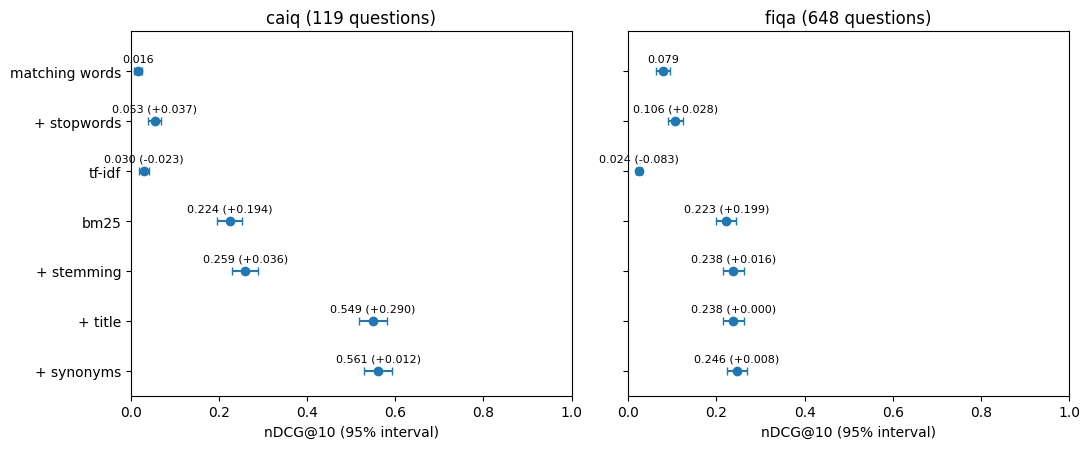

In [18]:
WITHOUT = {ds.name: BODY[ds.name] + TITLE[ds.name] for ds in DATASETS}
BODY = {ds.name: lab.bm25(ds, ds.bodies, idf_texts=ds.title_body, analyzer=ANALYZER) for ds in DATASETS}
TITLE = {ds.name: lab.bm25(ds, ds.titles, idf_texts=ds.title_body, analyzer=ANALYZER) for ds in DATASETS}
for ds in DATASETS:
    runs[ds.name]["+ synonyms"] = lab.evaluate(ds, BODY[ds.name] + TITLE[ds.name])
example = lab.example(caiq, runs["caiq"]["+ title"], runs["caiq"]["+ synonyms"])
lab.show(caiq, example, {"+ title": WITHOUT["caiq"], "+ synonyms": BODY["caiq"] + TITLE["caiq"]})
lab.plot_ladder(runs);

## 11. Saturated BM25

BM25 saturates term frequency within a field, but the overall BM25 scores are unbounded, they can range to some fairly high values. In CAIQ, some long answers repeat the same few sentences and rank high for many questions this way.

We would like all component scores in a ranking algorithm to be normalized to the same scale (in practice, between 0 and 1) so that we can combine them in linear combinations. In practice, we have found good results by saturating each field BM25 score as well, score / (S + score), so that each field score is normalized to 0-1.

$$s(q, d) = \sum_{f \in \{\mathrm{body},\, \mathrm{title}\}} \frac{\mathrm{BM25}_f(q, d)}{S + \mathrm{BM25}_f(q, d)}$$

where $\mathrm{BM25}_f(q, d)$ is the BM25 score of field $f$, and $S$ is the field score at which the saturated score reaches one half.

caiq: nDCG@10 0.561 before, 0.542 after; better 39, worse 63 of 119 questions; fixed 0, broken 0 (from below 0.3 to above 0.7, or back)



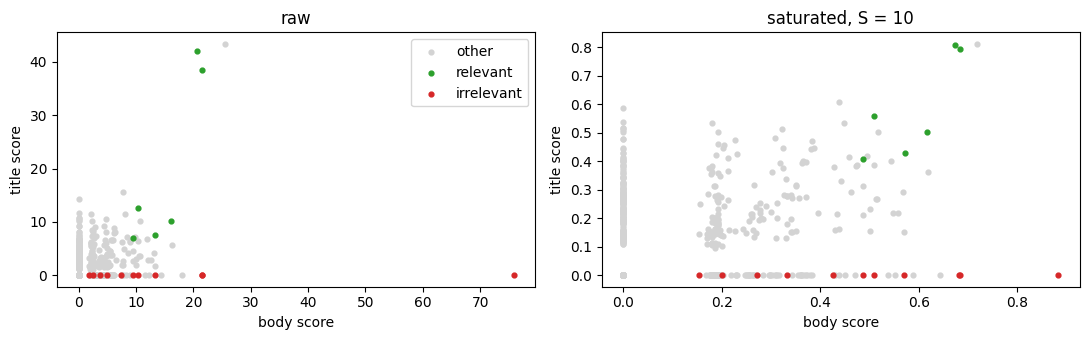

In [19]:
def saturated(ds, S):
    return BODY[ds.name] / (S + BODY[ds.name]) + TITLE[ds.name] / (S + TITLE[ds.name])

example = lab.example(caiq, runs["caiq"]["+ synonyms"], lab.evaluate(caiq, saturated(caiq, 10)))
body, title = BODY["caiq"][caiq.qrow[example]], TITLE["caiq"][caiq.qrow[example]]
words = [lab.tokenize(t) for t in caiq.bodies]  # long answers whose last 200 words are under 9% distinct: repeated sentences
is_irr = np.array([len(w) > 200 and len(set(w[-200:])) < 18 for w in words])
is_rel = np.array([caiq.qrels[example].get(d, 0) > 0 for d in caiq.ids])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (name, f) in zip(axes, (("raw", lambda x: x), ("saturated, S = 10", lambda x: x / (10 + x)))):
    for mask, label, color in ((~is_irr & ~is_rel, "other", "lightgrey"), (is_rel, "relevant", "C2"), (is_irr, "irrelevant", "C3")):
        ax.scatter(f(body[mask]), f(title[mask]), s=12, color=color, label=label)
    ax.set_xlabel("body score")
    ax.set_ylabel("title score")
    ax.set_title(name)
axes[0].legend()
fig.tight_layout()

{2: np.float64(0.523), 5: np.float64(0.534), 10: np.float64(0.542), 25: np.float64(0.567), 50: np.float64(0.567), 100: np.float64(0.563)}


                      caiq               fiqa         
matching words       0.016              0.079         
+ stopwords          0.053 (+0.037)     0.106 (+0.028)
tf-idf               0.030 (-0.023)     0.024 (-0.083)
bm25                 0.224 (+0.194)     0.223 (+0.199)
+ stemming           0.259 (+0.036)     0.238 (+0.016)
+ title              0.549 (+0.290)     0.238 (+0.000)
+ synonyms           0.561 (+0.012)     0.246 (+0.008)
saturated            0.567 (+0.006)     0.246 (+0.000)


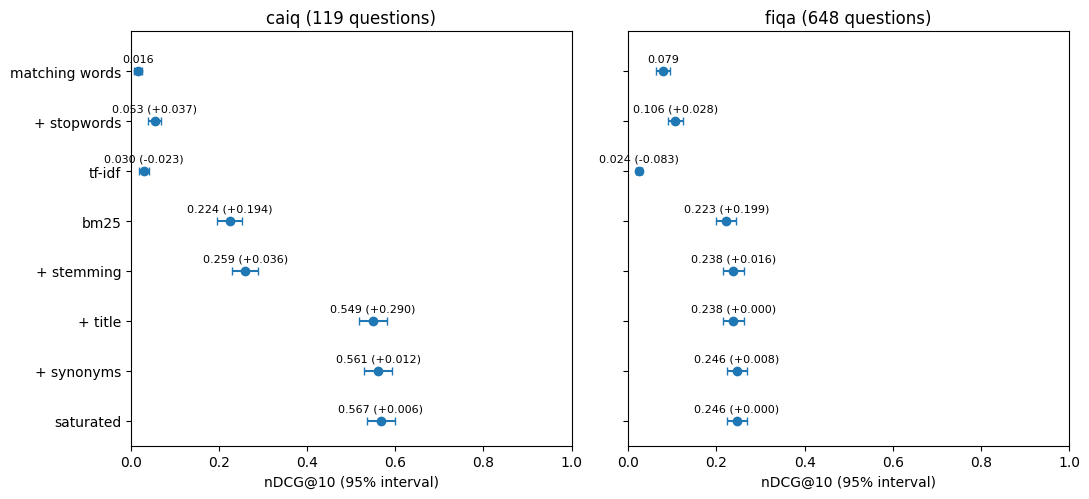

In [20]:
grid = {S: np.mean(list(lab.evaluate(caiq, saturated(caiq, S)).values())) for S in (2, 5, 10, 25, 50, 100)}
print({S: round(v, 3) for S, v in grid.items()})
S = max(grid, key=grid.get)
for ds in DATASETS:
    runs[ds.name]["saturated"] = lab.evaluate(ds, saturated(ds, S))
lab.plot_ladder(runs);

In [21]:
lab.show(caiq, example, {"+ synonyms": BODY["caiq"] + TITLE["caiq"], "saturated": saturated(caiq, S)})

q:octopus:IAM-06.2: For Octopus Deploy: Are controls in place to prevent unauthorized access to tenant application, program, or object source code, and assure it is restricted to authorized personnel only?

+ synonyms  nDCG@10 0.580
  1. [.] misc:010       Untitled NA. For the purpose of the questionnaire the question is not applicable, since wi…
  2. [1] octopus:IAM-06.1 Octopus Deploy — IAM-06.1: Are controls in place to prevent unauthorized access to your ap…
  3. [1] realigned:IAM-06.1 Realigned Technologies — IAM-06.1: Are controls in place to prevent unauthorized access to…
  4. [1] octopus:IAM-02.1 Octopus Deploy — IAM-02.1: Do you have controls in place ensuring timely removal of system…
  5. [.] octopus:CCC-04.1 Octopus Deploy — CCC-04.1: Do you have controls in place to restrict and monitor the insta…

saturated  nDCG@10 0.832
  1. [1] octopus:IAM-06.1 Octopus Deploy — IAM-06.1: Are controls in place to prevent unauthorized access to your ap…
  2. [1] realigned:IAM-06.1 Reali

## 12. Phrase match boosting

So far, each document is a *bag of words*: the order of the terms does not matter, so "data at rest" and "rest data" score the same. The positional index from section 3 lets us use *proximity*. We score the share of the question's neighbouring term pairs that also occur next to each other in the document, and add it to the score with a small weight:

$$\mathrm{phrase}(q, d) = \frac{\lvert \{ (t_i, t_{i+1}) \in P(q) : t_i \text{ and } t_{i+1} \text{ occur next to each other in } d \} \rvert}{\lvert P(q) \rvert}$$

$$s'(q, d) = s(q, d) + w \left( 0.5 \cdot \mathrm{phrase}(q, \mathrm{body}_d) + \mathrm{phrase}(q, \mathrm{title}_d) \right)$$

where $P(q)$ is the set of the question's neighbouring term pairs, $s(q, d)$ the saturated score from section 11, and $w$ the small weight (0.2), chosen with the plot below.

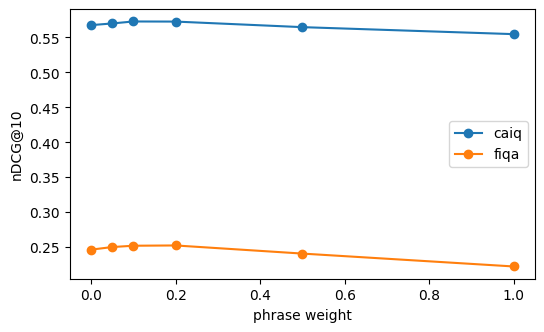

In [22]:
PHRASE_BODY = {ds.name: lab.phrase(ds, ds.bodies, ANALYZER) for ds in DATASETS}
PHRASE_TITLE = {ds.name: lab.phrase(ds, ds.titles, ANALYZER) for ds in DATASETS}
PHRASE = {n: 0.5 * PHRASE_BODY[n] + PHRASE_TITLE[n] for n in PHRASE_BODY}

def lexical(ds, w=0.2):
    return saturated(ds, S) + w * PHRASE[ds.name]

weights = (0, 0.05, 0.1, 0.2, 0.5, 1)
fig, ax = plt.subplots(figsize=(6, 3.5))
for ds in DATASETS:
    ax.plot(weights, [np.mean(list(lab.evaluate(ds, lexical(ds, w)).values())) for w in weights], marker="o", label=ds.name)
ax.set_xlabel("phrase weight")
ax.set_ylabel("nDCG@10")
ax.legend()

                      caiq               fiqa         
matching words       0.016              0.079         
+ stopwords          0.053 (+0.037)     0.106 (+0.028)
tf-idf               0.030 (-0.023)     0.024 (-0.083)
bm25                 0.224 (+0.194)     0.223 (+0.199)
+ stemming           0.259 (+0.036)     0.238 (+0.016)
+ title              0.549 (+0.290)     0.238 (+0.000)
+ synonyms           0.561 (+0.012)     0.246 (+0.008)
saturated            0.567 (+0.006)     0.246 (+0.000)
+ phrase             0.572 (+0.005)     0.252 (+0.006)


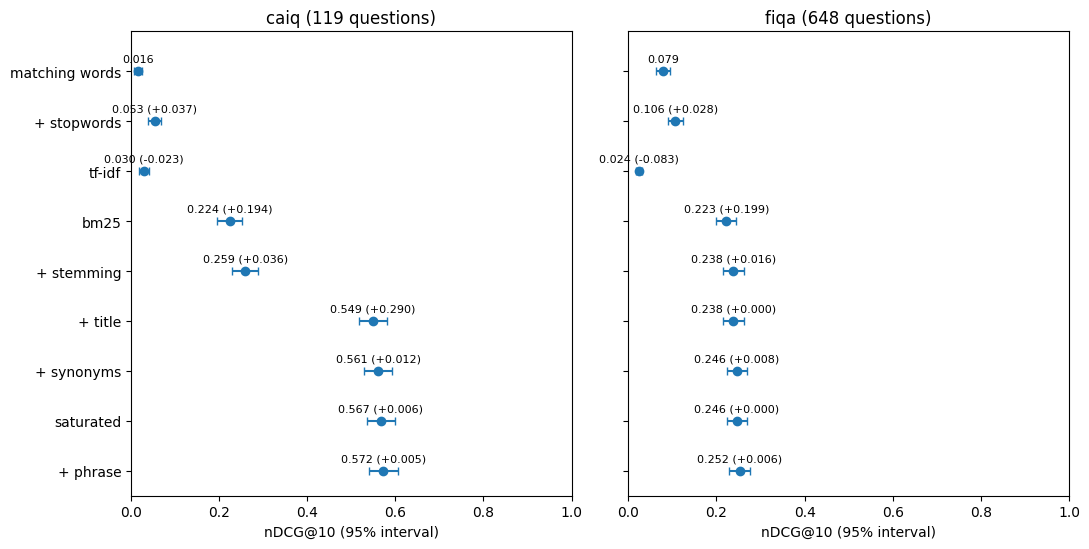

In [23]:
for ds in DATASETS:
    runs[ds.name]["+ phrase"] = lab.evaluate(ds, lexical(ds))
lab.plot_ladder(runs);

In [24]:
gain = {q: runs["fiqa"]["+ phrase"][q] - runs["fiqa"]["saturated"][q] for q in fiqa.qids}
example = max(gain, key=gain.get)
lab.show(fiqa, example, {"saturated": saturated(fiqa, S), "+ phrase": lexical(fiqa)})

7801: What are some well known or well regarded arguments against investing?

saturated  nDCG@10 0.387
  1. [.] 473434         On the contrary. Outsourcing to India and investing in India in general is quite profitabl…
  2. [1] 252574         "I think you're confusing risk analysis (that is what you quoted as ""Taleb Distribution""…
  3. [.] 71292          Some financial planners would not advise one way or the other on a specific stock without …
  4. [.] 355283         I can understand the argument that it's not a good allocation of resources to extend the l…
  5. [.] 246356         "&gt;Good luck arguing that in court while defending non-payment of taxes. Might want to l…

+ phrase  nDCG@10 0.818
  1. [1] 252574         "I think you're confusing risk analysis (that is what you quoted as ""Taleb Distribution""…
  2. [.] 473434         On the contrary. Outsourcing to India and investing in India in general is quite profitabl…
  3. [.] 355283         I can understand the argument that i

## 13. Learning to rank

The current ranking function combines several scores (body, title, phrase) using linear weights chosen by hand. Learning to rank learns these weights from relevance judgments in the data instead.

Each question's top 50 documents become training examples, with the different scores we have defined so far used as *features* in the learning model. A linear model trained with LambdaRank, which optimizes the ranking directly, gives one weight per feature; LightGBM learns a tree model, which can combine features in nonlinear ways.

$$s(q, d) = \sum_{j} w_j \, x_j(q, d)$$

where $x_j(q, d)$ is the $j$-th feature (one of the scores above) and $w_j$ its learned weight.

To measure honestly, we split the data into 5 shards, train on 4 shards of questions at a time and test on the remaining one (5-fold *cross-validation*). The feature importance table shows which features matter:

In [25]:
import lightgbm as lgb

LEX_TOP = {ds.name: lab.topk(ds, lexical(ds), 50) for ds in DATASETS}
FEATURES = ("bm25 body", "bm25 title", "phrase body", "phrase title")

def parts(ds):
    """The lexical formula's parts, as the formula uses them."""
    n = ds.name
    return [BODY[n] / (S + BODY[n]), TITLE[n] / (S + TITLE[n]), PHRASE_BODY[n], PHRASE_TITLE[n]]

RAW = {ds.name: np.stack([np.take_along_axis(p, LEX_TOP[ds.name], 1) for p in parts(ds)], -1) for ds in DATASETS}
SCALE = {n: (x.mean((0, 1)), np.maximum(x.std((0, 1)), 1e-9)) for n, x in RAW.items()}
X = {n: (x - SCALE[n][0]) / SCALE[n][1] for n, x in RAW.items()}
Y = {ds.name: lab.labels(ds, LEX_TOP[ds.name]) for ds in DATASETS}
GBM = dict(objective="lambdarank", learning_rate=0.05, num_leaves=7, deterministic=True, force_row_wise=True, verbose=-1)

def linear(x, y, ideal, x_test):
    return x_test @ lab.lambdarank(x, y, ideal)

def lightgbm(x, y, ideal, x_test):
    model = lgb.train(GBM, lgb.Dataset(x.reshape(-1, x.shape[-1]), y.reshape(-1), group=[x.shape[1]] * len(x)), 200)
    return model.predict(x_test.reshape(-1, x.shape[-1])).reshape(x_test.shape[:2])

LTR = {fit.__name__: {ds.name: lab.cross_validate(ds, X[ds.name], Y[ds.name], fit) for ds in DATASETS} for fit in (linear, lightgbm)}

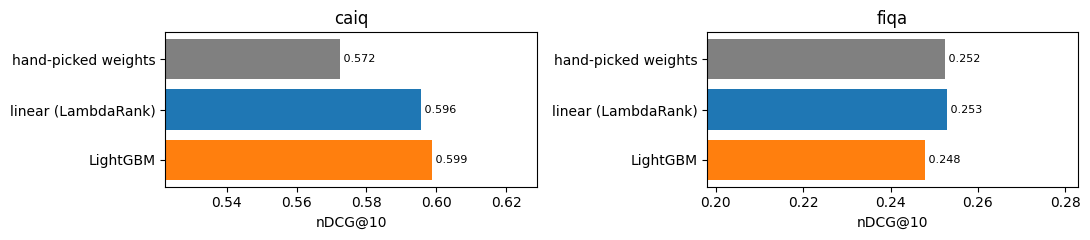

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 2.5))
for ax, ds in zip(axes, DATASETS):
    bars = {"hand-picked weights": np.take_along_axis(lexical(ds), LEX_TOP[ds.name], 1),
            "linear (LambdaRank)": LTR["linear"][ds.name], "LightGBM": LTR["lightgbm"][ds.name]}
    v = [np.mean(list(lab.evaluate_top(ds, LEX_TOP[ds.name], s).values())) for s in bars.values()]
    ax.barh(list(bars), v, color=["grey", "C0", "C1"])
    for k, x in enumerate(v):
        ax.text(x, k, f" {x:.3f}", va="center", fontsize=8)
    ax.set_xlim(min(v) - 0.05, max(v) + 0.03)
    ax.invert_yaxis()
    ax.set_title(ds.name)
    ax.set_xlabel("nDCG@10")
fig.tight_layout()

In [27]:
def fit_all(ds, x):
    """Mean nDCG@10 of the linear score trained on every question (in-sample: it only compares features)."""
    return np.mean(list(lab.evaluate_top(ds, LEX_TOP[ds.name], x @ lab.lambdarank(x, Y[ds.name], lab.ideal_dcg(ds))).values()))

for ds in DATASETS:
    w = lab.lambdarank(X[ds.name], Y[ds.name], lab.ideal_dcg(ds)) / SCALE[ds.name][1]  # weights on the formula's own parts
    w = w / w.max()
    print(f"{ds.name}: score = " + " + ".join(f"{v:.2f} · {f}" for f, v in zip(FEATURES, w) if v > 1e-3))

importance, full = {}, {}
for ds in DATASETS:
    booster = lgb.train(GBM, lgb.Dataset(X[ds.name].reshape(-1, len(FEATURES)), Y[ds.name].reshape(-1), group=[50] * len(ds.qids)), 200)
    gain = booster.feature_importance("gain") / max(booster.feature_importance("gain").sum(), 1e-9)
    full[ds.name] = fit_all(ds, X[ds.name])
    for i, f in enumerate(FEATURES):
        importance[ds.name, f] = (gain[i], fit_all(ds, np.delete(X[ds.name], i, -1)))
print(f"\n{'':16s}" + "".join(f"{ds.name + ' gain':>12s}{ds.name + ' nDCG without':>20s}" for ds in DATASETS))
print(f"{'(all features)':16s}" + "".join(f"{'':12s}{full[ds.name]:20.3f}" for ds in DATASETS))
for f in FEATURES:
    print(f"{f:16s}" + "".join(f"{importance[ds.name, f][0]:12.0%}{importance[ds.name, f][1]:20.3f}" for ds in DATASETS))

caiq: score = 0.54 · bm25 body + 1.00 · bm25 title + 0.05 · phrase title


fiqa: score = 1.00 · bm25 body + 0.06 · phrase body



                   caiq gain   caiq nDCG without   fiqa gain   fiqa nDCG without
(all features)                             0.596                           0.253
bm25 body                23%               0.547         85%               0.204
bm25 title               72%               0.515          0%               0.253
phrase body               2%               0.596         15%               0.246
phrase title              3%               0.596          0%               0.253


                        caiq               fiqa         
matching words         0.016              0.079         
+ stopwords            0.053 (+0.037)     0.106 (+0.028)
tf-idf                 0.030 (-0.023)     0.024 (-0.083)
bm25                   0.224 (+0.194)     0.223 (+0.199)
+ stemming             0.259 (+0.036)     0.238 (+0.016)
+ title                0.549 (+0.290)     0.238 (+0.000)
+ synonyms             0.561 (+0.012)     0.246 (+0.008)
saturated              0.567 (+0.006)     0.246 (+0.000)
+ phrase               0.572 (+0.005)     0.252 (+0.006)
learning to rank       0.596 (+0.023)     0.253 (+0.000)


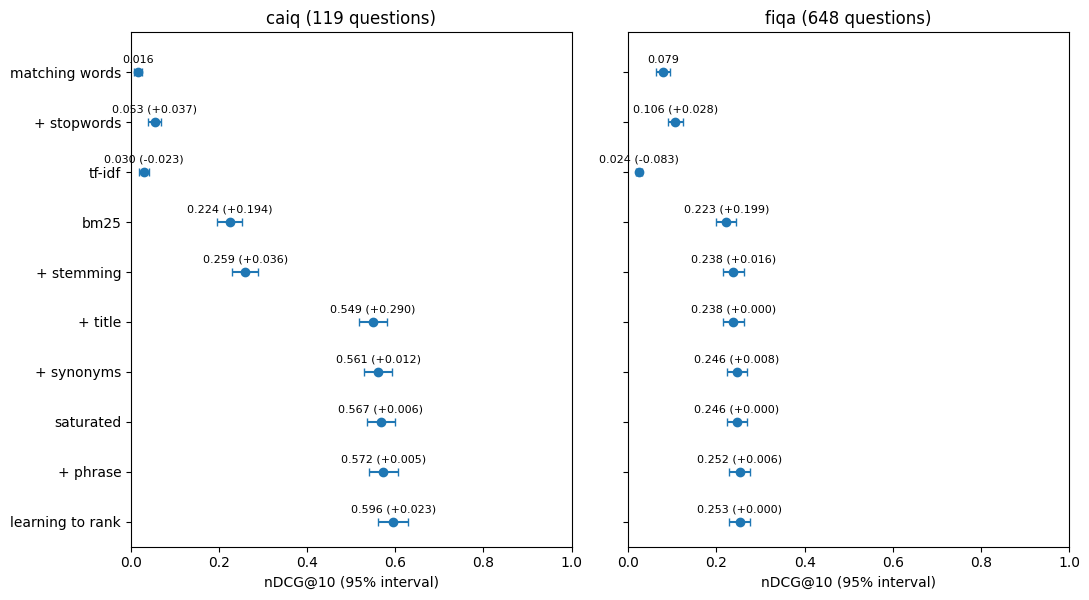

In [28]:
for ds in DATASETS:
    runs[ds.name]["learning to rank"] = lab.evaluate_top(ds, LEX_TOP[ds.name], LTR["linear"][ds.name])
lab.plot_ladder(runs);

In [29]:
gain = {q: runs["caiq"]["learning to rank"][q] - runs["caiq"]["+ phrase"][q] for q in caiq.qids}
example = max(gain, key=gain.get)
lab.show(caiq, example, {"+ phrase": lexical(caiq), "learning to rank": lab.expand(caiq, LEX_TOP["caiq"], LTR["linear"]["caiq"])})

q:fimil:LOG-06.1: For Fimil: Is a reliable time source being used across all relevant systems?

+ phrase  nDCG@10 0.387
  1. [.] misc:002       Untitled Yes. Incident Response Plan defines customer notification procedures for data bre…
  2. [1] present:LOG-06.1 Present SpA — LOG-06.1: Is a reliable time source being used across all relevant informati…
  3. [.] octopus:TVM-01.1 Octopus Deploy — TVM-01.1: Do you have anti-malware programs that support or connect to yo…
  4. [.] octopus:IVS-12.3 Octopus Deploy — IVS-12.3: Are policies and procedures established and mechanisms implemen…
  5. [.] fimil:TVM-05.1 Fimil — TVM-05.1: Are processes to identify updates for applications using third-party lib…

learning to rank  nDCG@10 0.818
  1. [1] present:LOG-06.1 Present SpA — LOG-06.1: Is a reliable time source being used across all relevant informati…
  2. [.] misc:002       Untitled Yes. Incident Response Plan defines customer notification procedures for data bre…
  3. [.] octopus:TVM-02.5 O

## 14. Vector search

Term-based lexical search is limited to matching shared vocabulary between the question and the document, and a synonym list only covers a few known cases of vocabulary mismatch. We can use neural networks to *embed* the question and each document in a vector space, so that texts with similar meaning are close even with no shared terms, and *cosine similarity* measures the similarity of documents to queries. Our embedding model reads the whole document, up to 8,192 tokens (the tokens from the model's tokenizer, not terms), so the vector of a long document describes all of it. The documents in both datasets are fairly short passages.

$$\cos(q, d) = \frac{\mathbf{q} \cdot \mathbf{d}}{\lVert \mathbf{q} \rVert \, \lVert \mathbf{d} \rVert}$$

where $\mathbf{q}$ and $\mathbf{d}$ are the embedding vectors of the question and the document.

Cosine similarity lies between −1 and 1. Our saturated lexical score from section 11 is bounded to 0-1, which enables us to combine both scores in a weighted sum of the two. An alternative for combining unbounded scores is *reciprocal rank fusion (RRF)*. This can be superior in some cases, but we have generally found it to underperform a weighted sum of normalized scores.

$$s(q, d) = 4 \max\left(0,\ \cos(q, d) - 0.05\right) + s'(q, d)$$

where $s'(q, d)$ is the lexical score with phrases from section 12; the weight 4 and the offset 0.05 were chosen on these questions.

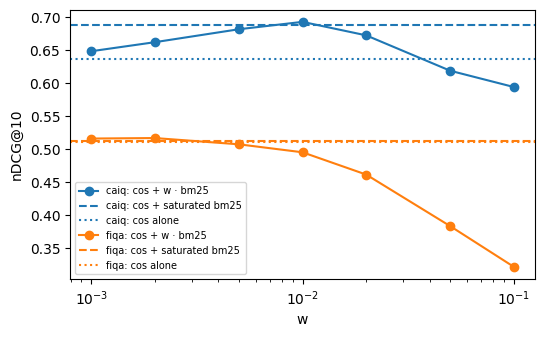

In [30]:
VEC = {ds.name: lab.vectors(ds) for ds in DATASETS}
COS = {name: q @ d.T for name, (d, q) in VEC.items()}
dense = {ds.name: lab.evaluate(ds, COS[ds.name]) for ds in DATASETS}

def naive(ds, w):
    return COS[ds.name] + w * (BODY[ds.name] + TITLE[ds.name])

def hybrid(ds):
    return 4 * np.maximum(0, COS[ds.name] - 0.05) + lexical(ds)

weights = (0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1)
fig, ax = plt.subplots(figsize=(6, 3.5))
for ds in DATASETS:
    curve = [np.mean(list(lab.evaluate(ds, naive(ds, w)).values())) for w in weights]
    ax.plot(weights, curve, marker="o", label=f"{ds.name}: cos + w · bm25")
    color = ax.lines[-1].get_color()
    ax.axhline(np.mean(list(lab.evaluate(ds, hybrid(ds)).values())), ls="--", color=color, label=f"{ds.name}: cos + saturated bm25")
    ax.axhline(np.mean(list(dense[ds.name].values())), ls=":", color=color, label=f"{ds.name}: cos alone")
ax.set_xscale("log")
ax.set_xlabel("w")
ax.set_ylabel("nDCG@10")
ax.legend(fontsize=7)

                        caiq               fiqa         
matching words         0.016              0.079         
+ stopwords            0.053 (+0.037)     0.106 (+0.028)
tf-idf                 0.030 (-0.023)     0.024 (-0.083)
bm25                   0.224 (+0.194)     0.223 (+0.199)
+ stemming             0.259 (+0.036)     0.238 (+0.016)
+ title                0.549 (+0.290)     0.238 (+0.000)
+ synonyms             0.561 (+0.012)     0.246 (+0.008)
saturated              0.567 (+0.006)     0.246 (+0.000)
+ phrase               0.572 (+0.005)     0.252 (+0.006)
learning to rank       0.596 (+0.023)     0.253 (+0.000)
+ dense                0.688 (+0.092)     0.512 (+0.259)


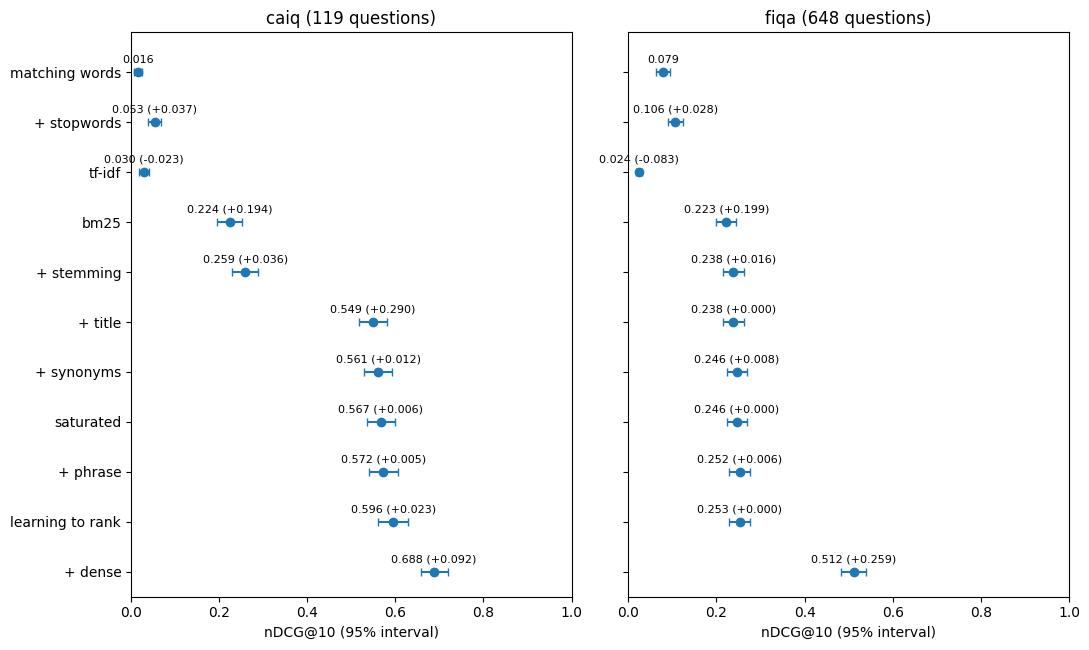

In [31]:
for ds in DATASETS:
    runs[ds.name]["+ dense"] = lab.evaluate(ds, hybrid(ds))
lab.plot_ladder(runs);

In [32]:
gain = {q: runs["fiqa"]["+ dense"][q] - runs["fiqa"]["+ phrase"][q] for q in fiqa.qids}
example = max(gain, key=gain.get)
lab.show(fiqa, example, {"+ phrase": lexical(fiqa), "+ dense": hybrid(fiqa)})

15: Can I send a money order from USPS as a business?

+ phrase  nDCG@10 0.000
  1. [.] 420483         On your end of the deal, the biggest risk is probably counterfeiting. That said, I'd think…
  2. [.] 230003         "&gt; ""So I'll either stop shipping prescriptions or switch to FedEx or UPS -- which cost…
  3. [.] 321826         Not sure why USPS wouldn't put the screws to stamps.com. Stamps might be sending a lot of …
  4. [.] 224000         "A money order is basically a pre-paid check. The physical cash would probably get deposit…
  5. [.] 454734         The net benefit to the US economy for the DoD is likely positive thanks to the Navy alone,…

+ dense  nDCG@10 1.000
  1. [1] 325273         Sure you can. You can fill in whatever you want in the From section of a money order, so y…
  2. [.] 224000         "A money order is basically a pre-paid check. The physical cash would probably get deposit…
  3. [.] 420483         On your end of the deal, the biggest risk is probably counter

## 15. Binarized embeddings

A float32 vector of 1,024 dimensions takes 4 KB per document, and at production scale, both memory and search time matter. To optimize for storage and compute constraints, we lower the precision of each document vector all the way to binary, using a sign function, resulting in a 32x reduction in storage. Subtracting the mean vector first (*centering*) keeps more information in the signs. We can still keep the queries in full-precision, and score a float query against binary documents, to keep most of the quality. The first stage now takes the top 20 from the binary vector similarity score and the top 20 from the lexical score, and scores these candidates with both:

$$\mathbf{b}(d) = \mathrm{sign}(\mathbf{d} - \boldsymbol{\mu}), \qquad s(q, d) = \frac{(\mathbf{q} - \boldsymbol{\mu}) \cdot \mathbf{b}(d)}{\sqrt{D}}$$

where $\boldsymbol{\mu}$ is the mean document vector, $D = 1024$ the number of dimensions, and $\mathbf{b}(d)$ holds one bit per dimension, $+1$ or $-1$.

In [33]:
def signs(x):
    return np.where(x >= 0, 1, -1).astype(np.float32)

BIN, CENTERED, ASYM = {}, {}, {}
for ds in DATASETS:
    d, q = VEC[ds.name]
    mean = d.mean(0)
    BIN[ds.name] = signs(q) @ signs(d).T
    CENTERED[ds.name] = signs(q - mean) @ signs(d - mean).T
    ASYM[ds.name] = (q - mean) @ signs(d - mean).T / np.sqrt(d.shape[1])  # the question stays float; documents are bits
    print(f"{ds.name}: {d.nbytes / 1e6:.1f} MB as float32, {np.packbits(d >= 0, axis=1).nbytes / 1e6:.2f} MB as bits; "
          f"nDCG@10 float {np.mean(list(dense[ds.name].values())):.3f}, "
          f"bits {np.mean(list(lab.evaluate(ds, BIN[ds.name]).values())):.3f}, "
          f"centered bits {np.mean(list(lab.evaluate(ds, CENTERED[ds.name]).values())):.3f}, "
          f"float question × centered bits {np.mean(list(lab.evaluate(ds, ASYM[ds.name]).values())):.3f}")

caiq: 2.6 MB as float32, 0.08 MB as bits; nDCG@10 float 0.636, bits 0.598, centered bits 0.608, float question × centered bits 0.618


fiqa: 237.2 MB as float32, 7.41 MB as bits; nDCG@10 float 0.511, bits 0.483, centered bits 0.485, float question × centered bits 0.503


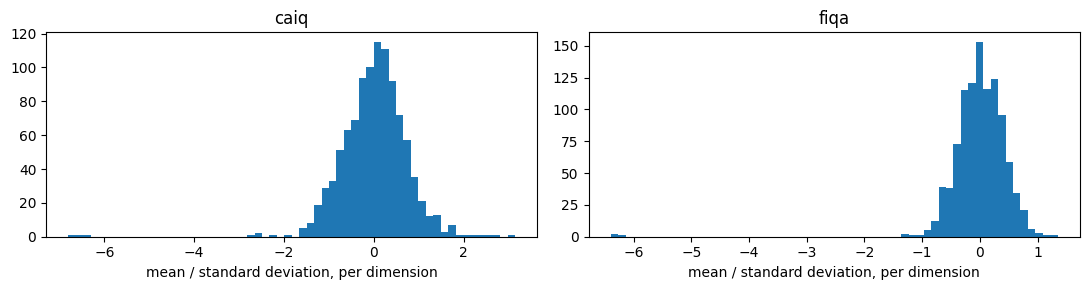

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, ds in zip(axes, DATASETS):
    d, _ = VEC[ds.name]
    ax.hist(d.mean(0) / d.std(0), bins=60)
    ax.set_title(ds.name)
    ax.set_xlabel("mean / standard deviation, per dimension")
fig.tight_layout()

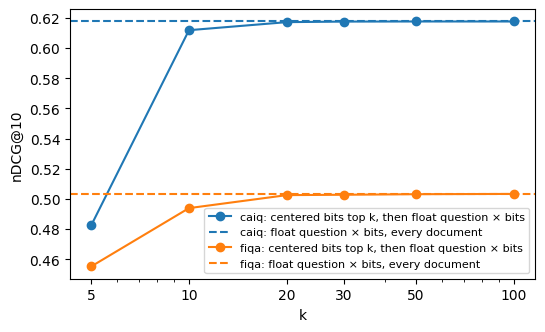

In [35]:
windows = (5, 10, 20, 30, 50, 100)
fig, ax = plt.subplots(figsize=(6, 3.5))
for ds in DATASETS:
    top = lab.topk(ds, CENTERED[ds.name], max(windows))  # the bits' top 100, once; each window is a prefix of it
    asym = np.take_along_axis(ASYM[ds.name], top, 1)
    curve = [np.mean(list(lab.evaluate_top(ds, top[:, :k], asym[:, :k]).values())) for k in windows]
    ax.plot(windows, curve, marker="o", label=f"{ds.name}: centered bits top k, then float question × bits")
    ax.axhline(np.mean(list(lab.evaluate(ds, ASYM[ds.name]).values())), ls="--", color=ax.lines[-1].get_color(),
               label=f"{ds.name}: float question × bits, every document")
ax.set_xscale("log")
ax.set_xticks(windows, windows)
ax.set_xlabel("k")
ax.set_ylabel("nDCG@10")
ax.legend(fontsize=8)

                          caiq               fiqa         
matching words           0.016              0.079         
+ stopwords              0.053 (+0.037)     0.106 (+0.028)
tf-idf                   0.030 (-0.023)     0.024 (-0.083)
bm25                     0.224 (+0.194)     0.223 (+0.199)
+ stemming               0.259 (+0.036)     0.238 (+0.016)
+ title                  0.549 (+0.290)     0.238 (+0.000)
+ synonyms               0.561 (+0.012)     0.246 (+0.008)
saturated                0.567 (+0.006)     0.246 (+0.000)
+ phrase                 0.572 (+0.005)     0.252 (+0.006)
learning to rank         0.596 (+0.023)     0.253 (+0.000)
+ dense                  0.688 (+0.092)     0.512 (+0.259)
binary first stage       0.684 (-0.004)     0.505 (-0.007)


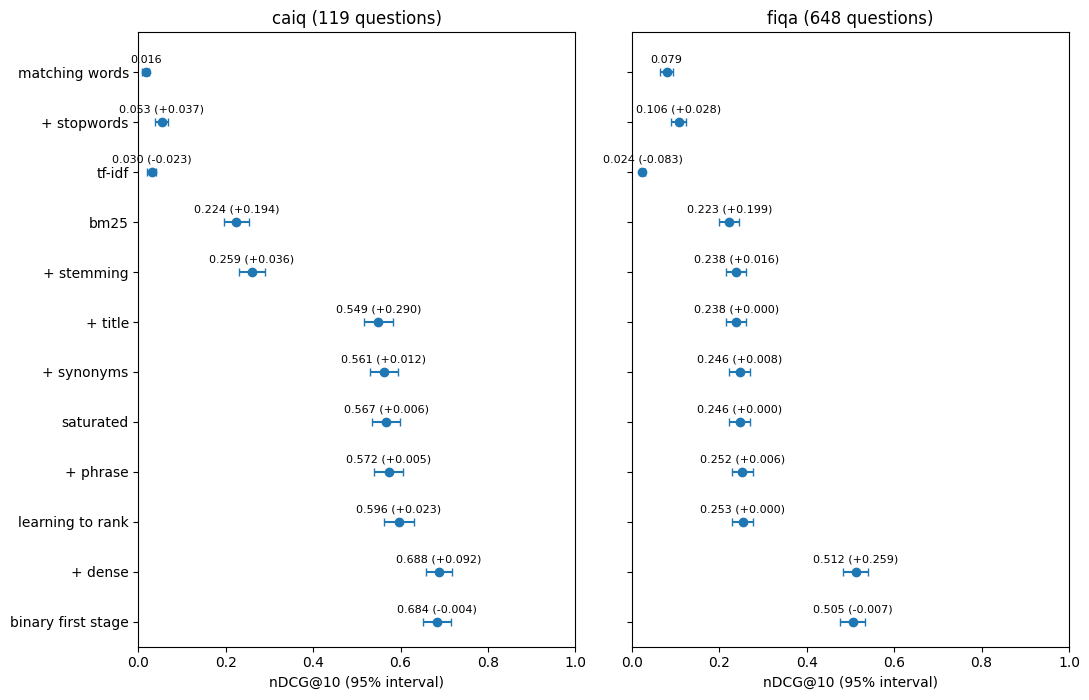

In [36]:
def hybrid_bits(ds):
    return 4 * np.maximum(0, ASYM[ds.name]) + lexical(ds)

CAND = {ds.name: lab.candidates(ds, [CENTERED[ds.name], BODY[ds.name] + TITLE[ds.name]], 20) for ds in DATASETS}
for ds in DATASETS:
    runs[ds.name]["binary first stage"] = lab.evaluate(ds, np.where(CAND[ds.name], hybrid_bits(ds), -np.inf))
lab.plot_ladder(runs);

## 16. Late interaction

In a simple dense embedding, a single vector has to summarize a whole passage of text. Late interaction (ColBERT) keeps one vector per token instead, and scores a document by matching each question token to its best document token (*MaxSim*), summed over the question.

$$\mathrm{MaxSim}(q, d) = \sum_{i=1}^{\lvert q \rvert} \max_{1 \le j \le \lvert d \rvert} \mathbf{q}_i \cdot \mathbf{d}_j$$

where $\mathbf{q}_i$ is the vector of the question's $i$-th token, $\mathbf{d}_j$ the vector of the document's $j$-th token, and $\lvert q \rvert$ and $\lvert d \rvert$ their numbers of tokens.

In practice, computing MaxSim over the whole matching result set is not practical. To simulate this *two-stage* ranking algorithm, our late interaction reranks only the first stage's top 20. We use Perplexity's pplx-embed-v2-late-0.6b, and mix its score with the weighted sum score from the previous stage:

$$s(q, d) = \mathrm{minmax}\left(s_1(q, d)\right) + \lambda \, \mathrm{minmax}\left(\mathrm{MaxSim}(q, d)\right)$$

where $s_1$ is the first stage's score, $\mathrm{minmax}$ rescales a question's 20 candidate scores to the range 0 to 1, and $\lambda$ is read off the curves below.

In [37]:
STEP5 = {ds.name: np.where(CAND[ds.name], hybrid_bits(ds), -np.inf) for ds in DATASETS}
TOP20 = {ds.name: lab.topk(ds, STEP5[ds.name], 20) for ds in DATASETS}

def at(ds, scores):
    return np.take_along_axis(scores, TOP20[ds.name], 1)

def minmax(x):
    lo, hi = x.min(1, keepdims=True), x.max(1, keepdims=True)
    return (x - lo) / np.maximum(hi - lo, 1e-9)

TOK = {ds.name: lab.late_tokens(ds, ENCODE_ON_GPU) for ds in DATASETS}
d_bytes = 1024 * 2
for ds in DATASETS:
    n = np.diff(TOK[ds.name].start).mean()
    print(f"{ds.name}: dense, one vector per document: {d_bytes:,} bytes as float16, {d_bytes // 16:,} as bits; pplx v2-late, "
          f"{n:.0f} vectors of 128 per document: {n * 256:,.0f} bytes as float16, {n * 128:,.0f} as int8, {n * 16:,.0f} as bits")

caiq: dense, one vector per document: 2,048 bytes as float16, 128 as bits; pplx v2-late, 107 vectors of 128 per document: 27,379 bytes as float16, 13,689 as int8, 1,711 as bits
fiqa: dense, one vector per document: 2,048 bytes as float16, 128 as bits; pplx v2-late, 163 vectors of 128 per document: 41,622 bytes as float16, 20,811 as int8, 2,601 as bits


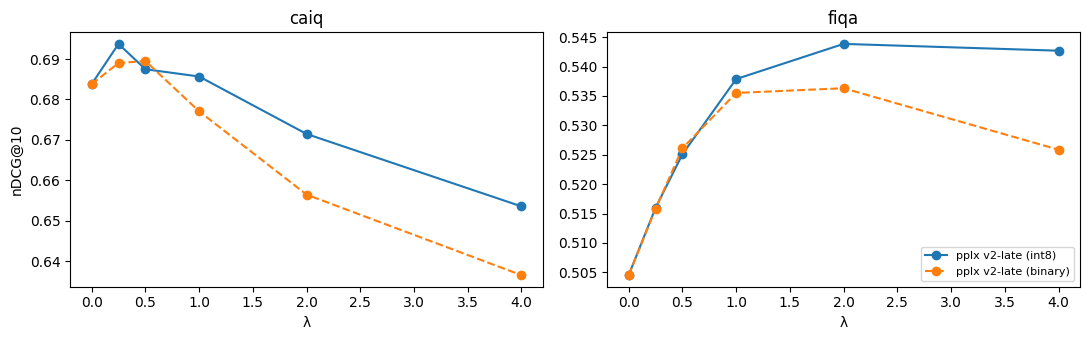

In [38]:
LATE = {form: {ds.name: lab.maxsim(ds, TOK[ds.name], TOP20[ds.name], binary=form == "binary") for ds in DATASETS}
        for form in ("int8", "binary")}

def fused(ds, scores, lam):
    return minmax(at(ds, STEP5[ds.name])) + lam * minmax(scores)

lams = (0, 0.25, 0.5, 1, 2, 4)
CURVE = {(form, ds.name): [np.mean(list(lab.evaluate_top(ds, TOP20[ds.name], fused(ds, LATE[form][ds.name], lam)).values()))
                           for lam in lams] for form in LATE for ds in DATASETS}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, ds in zip(axes, DATASETS):
    for form, ls in (("int8", "-"), ("binary", "--")):
        ax.plot(lams, CURVE[form, ds.name], ls=ls, marker="o", label=f"pplx v2-late ({form})")
    ax.set_title(ds.name)
    ax.set_xlabel("λ")
axes[0].set_ylabel("nDCG@10")
axes[1].legend(fontsize=8)
fig.tight_layout()

In [39]:
for ds in DATASETS:
    alone = {"step 5": at(ds, STEP5[ds.name]), **{f"pplx v2-late ({form})": LATE[form][ds.name] for form in LATE}}
    print(f"{ds.name}, the same top 20 ordered by " + ", ".join(
        f"{name} {np.mean(list(lab.evaluate_top(ds, TOP20[ds.name], s).values())):.3f}" for name, s in alone.items()))

caiq, the same top 20 ordered by step 5 0.684, pplx v2-late (int8) 0.630, pplx v2-late (binary) 0.618
fiqa, the same top 20 ordered by step 5 0.505, pplx v2-late (int8) 0.532, pplx v2-late (binary) 0.500


{'caiq': 0.5, 'fiqa': 2}
                          caiq               fiqa         
matching words           0.016              0.079         
+ stopwords              0.053 (+0.037)     0.106 (+0.028)
tf-idf                   0.030 (-0.023)     0.024 (-0.083)
bm25                     0.224 (+0.194)     0.223 (+0.199)
+ stemming               0.259 (+0.036)     0.238 (+0.016)
+ title                  0.549 (+0.290)     0.238 (+0.000)
+ synonyms               0.561 (+0.012)     0.246 (+0.008)
saturated                0.567 (+0.006)     0.246 (+0.000)
+ phrase                 0.572 (+0.005)     0.252 (+0.006)
learning to rank         0.596 (+0.023)     0.253 (+0.000)
+ dense                  0.688 (+0.092)     0.512 (+0.259)
binary first stage       0.684 (-0.004)     0.505 (-0.007)
+ late interaction       0.690 (+0.006)     0.536 (+0.032)


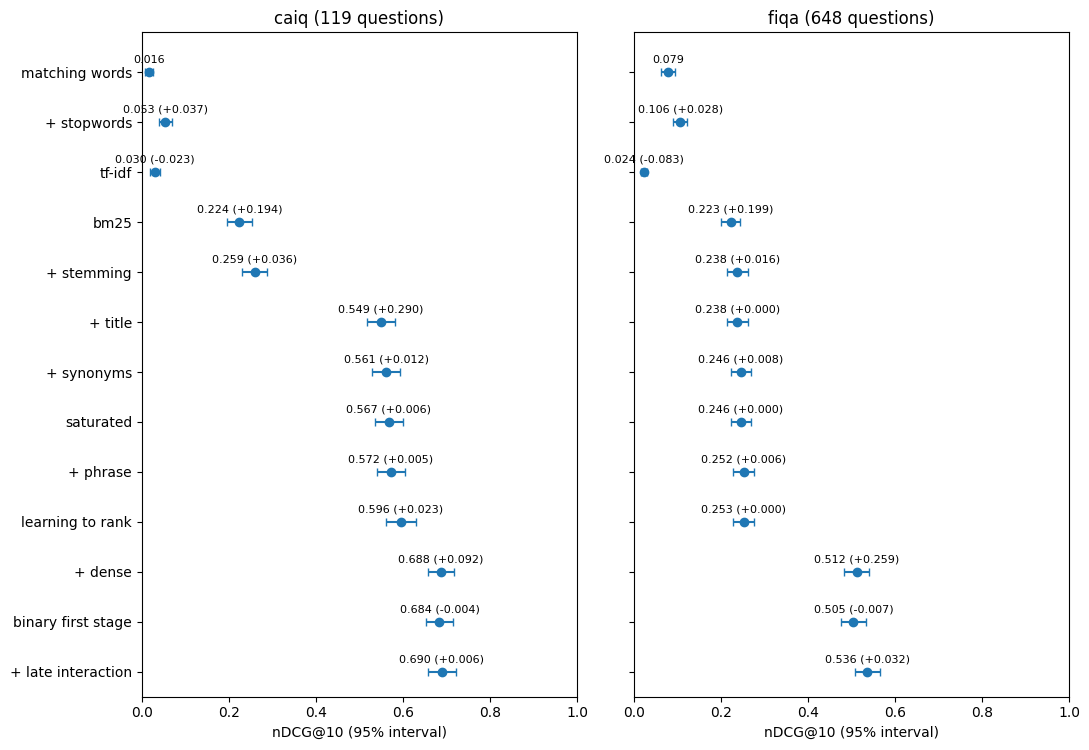

In [40]:
LAM_LATE = {ds.name: lams[int(np.argmax(CURVE["binary", ds.name]))] for ds in DATASETS}  # read off the curves above
print(LAM_LATE)
for ds in DATASETS:
    runs[ds.name]["+ late interaction"] = lab.evaluate_top(ds, TOP20[ds.name], fused(ds, LATE["binary"][ds.name], LAM_LATE[ds.name]))
lab.plot_ladder(runs);

In [41]:
for ds in DATASETS:
    n = np.diff(TOK[ds.name].start).mean()
    size = {"int8": n * 128, "binary": n * 16}
    print(f"{ds.name}: " + ", ".join(f"{form} {max(CURVE[form, ds.name]):.3f} ({size[form]:,.0f} bytes per document)" for form in LATE))

caiq: int8 0.694 (13,689 bytes per document), binary 0.690 (1,711 bytes per document)
fiqa: int8 0.544 (20,811 bytes per document), binary 0.536 (2,601 bytes per document)


## 17. Cross-encoder

Both dense and late interaction embedding models encode the question and the document separately (a *bi-encoder*) ahead of time, so the document vectors can be computed offline and only the similarity computation is required at query time. A cross-encoder reads the question and the document tokens together at query time and outputs a relevance score.

The cross-encoder is the most accurate ranking method but also the most expensive one, since nothing can be precomputed. It is commonly used in a *two-stage* design: a cheap first stage for recall followed by an expensive reranker for precision. The lab server calls Voyage rerank-3 for you; the scores of the notebook's top 20 are cached:

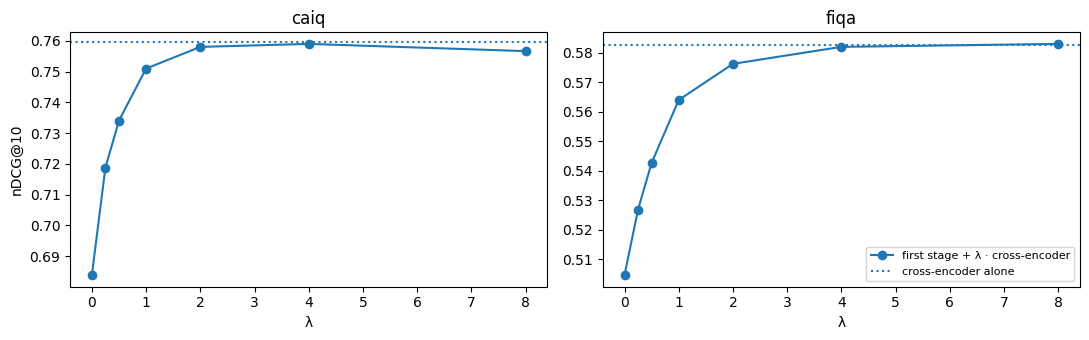

In [42]:
CE = {ds.name: lab.rerank(ds, TOP20[ds.name], "voyage-rerank-3") for ds in DATASETS}

def reranked(ds, lam):
    return minmax(at(ds, STEP5[ds.name])) + lam * minmax(CE[ds.name])

lams = (0, 0.25, 0.5, 1, 2, 4, 8)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, ds in zip(axes, DATASETS):
    ax.plot(lams, [np.mean(list(lab.evaluate_top(ds, TOP20[ds.name], reranked(ds, lam)).values())) for lam in lams],
            marker="o", label="first stage + λ · cross-encoder")
    ax.axhline(np.mean(list(lab.evaluate_top(ds, TOP20[ds.name], CE[ds.name]).values())), ls=":",
               color=ax.lines[-1].get_color(), label="cross-encoder alone")
    ax.set_title(ds.name)
    ax.set_xlabel("λ")
axes[0].set_ylabel("nDCG@10")
axes[1].legend(fontsize=8)
fig.tight_layout()

{'caiq': 4, 'fiqa': 8}
                          caiq               fiqa         
matching words           0.016              0.079         
+ stopwords              0.053 (+0.037)     0.106 (+0.028)
tf-idf                   0.030 (-0.023)     0.024 (-0.083)
bm25                     0.224 (+0.194)     0.223 (+0.199)
+ stemming               0.259 (+0.036)     0.238 (+0.016)
+ title                  0.549 (+0.290)     0.238 (+0.000)
+ synonyms               0.561 (+0.012)     0.246 (+0.008)
saturated                0.567 (+0.006)     0.246 (+0.000)
+ phrase                 0.572 (+0.005)     0.252 (+0.006)
learning to rank         0.596 (+0.023)     0.253 (+0.000)
+ dense                  0.688 (+0.092)     0.512 (+0.259)
binary first stage       0.684 (-0.004)     0.505 (-0.007)
+ late interaction       0.690 (+0.006)     0.536 (+0.032)
+ cross-encoder          0.759 (+0.069)     0.583 (+0.047)


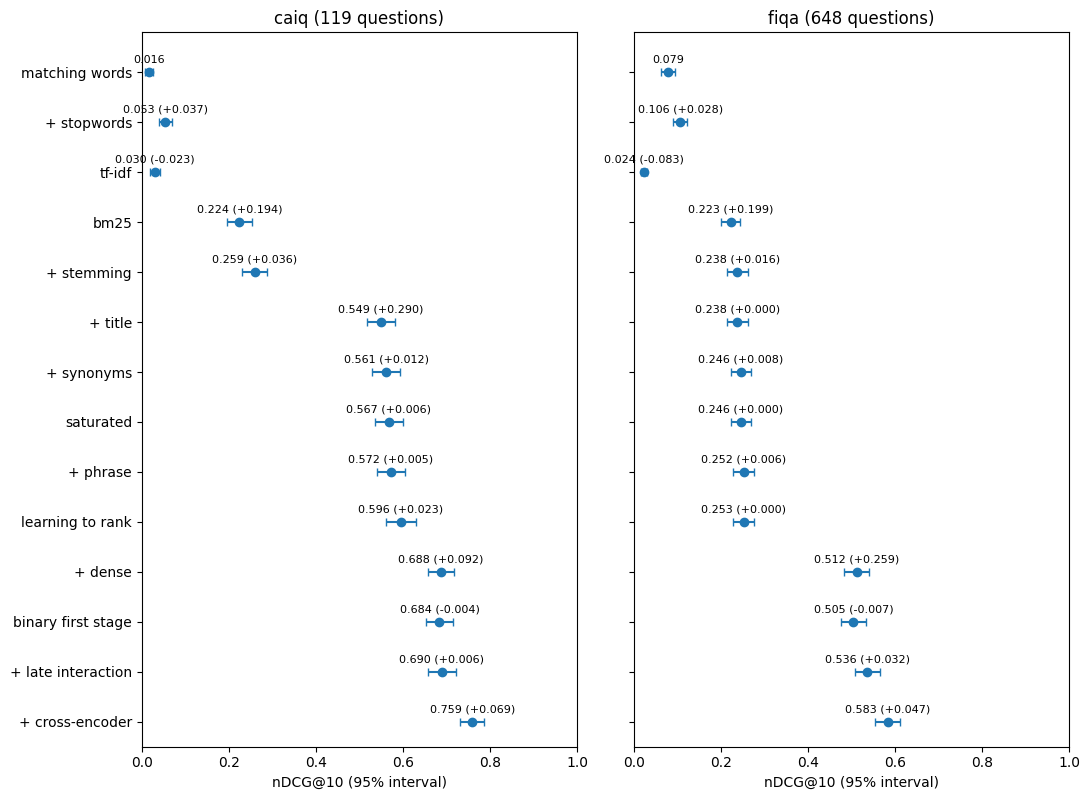

In [43]:
LAM_CE = {ds.name: max(lams, key=lambda lam: np.mean(list(lab.evaluate_top(ds, TOP20[ds.name], reranked(ds, lam)).values())))
          for ds in DATASETS}  # read off the curves above
print(LAM_CE)
for ds in DATASETS:
    runs[ds.name]["+ cross-encoder"] = lab.evaluate_top(ds, TOP20[ds.name], reranked(ds, LAM_CE[ds.name]))
lab.plot_ladder(runs);

In [44]:
gain = {q: runs["caiq"]["+ cross-encoder"][q] - runs["caiq"]["binary first stage"][q] for q in caiq.qids}
example = max(gain, key=gain.get)
lab.show(caiq, example, {"binary first stage": STEP5["caiq"],
                            "+ cross-encoder": lab.expand(caiq, TOP20["caiq"], reranked(caiq, LAM_CE["caiq"]))})

q:present:IAM-06.1: For Present SpA: Is a user access provisioning process defined and implemented which authorizes, records, and communicates data and assets access changes?

binary first stage  nDCG@10 0.399
  1. [.] present:IAM-14.1 Present SpA — IAM-14.1: Are processes, procedures, and technical measures for authenticati…
  2. [.] present:IAM-16.1 Present SpA — IAM-16.1: Are processes, procedures, and technical measures to verify access…
  3. [1] present:IAM-10.1 Present SpA — IAM-10.1: Is an access process defined and implemented to ensure privileged …
  4. [.] present:HRS-02.1 Present SpA — HRS-02.1: Are policies and procedures for defining allowances and conditions…
  5. [1] present:CCC-04.1 Present SpA — CCC-04.1: Is the unauthorized addition, removal, update, and management of o…

+ cross-encoder  nDCG@10 0.753
  1. [1] fimil:IAM-06.1 Fimil — IAM-06.1: Is a user access provisioning process defined and implemented? Yes. Emai…
  2. [.] present:IAM-16.1 Present SpA — IAM-16.1: Ar

## 18. Estimating uncertainty

Every number so far is a mean over a sample of questions: 119 in CAIQ, 648 in FiQA. Another sample would give a different mean, so a small difference between two steps may be noise. The *bootstrap* resamples the questions many times and gives a 95% interval for the mean. This gives us a cheap estimate of sampling uncertainty which does not depend on a lot of assumptions. You can use it on any kind of evaluation.

$$\bar{x}^{*}_{b} = \frac{1}{n} \sum_{i=1}^{n} x_{I_{b,i}}, \qquad b = 1, \dots, B$$

where $x_i$ is question $i$'s nDCG@10, $n$ the number of questions, and each $I_{b,i}$ a question index drawn at random, with replacement, from $1, \dots, n$. The 95% interval runs from the 2.5th to the 97.5th percentile of the $B = 10{,}000$ resampled means $\bar{x}^{*}_{b}$.

Obviously, many kinds of uncertainty are not captured by this interval, but we recommend using a bootstrap 95% CI as a basic diagnostic when evaluating changes. If your proposed change cannot clear this interval, it is not distinguishable from noise on the dataset. You need more data and/or a bigger improvement.

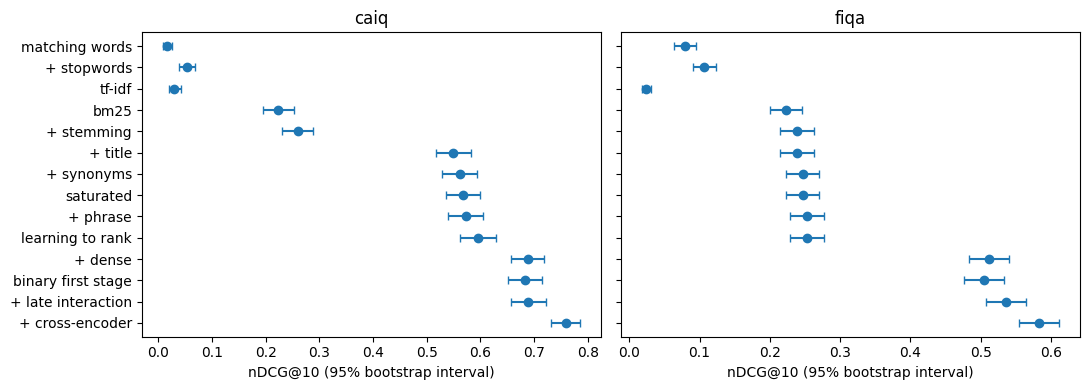

In [45]:
PER_Q = {ds.name: {step: np.array([r[q] for q in ds.qids]) for step, r in runs[ds.name].items()} for ds in DATASETS}
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, ds in zip(axes, DATASETS):
    steps = list(PER_Q[ds.name])
    for i, step in enumerate(steps):
        x = PER_Q[ds.name][step]
        lo, hi = lab.bootstrap(x)
        ax.errorbar(x.mean(), i, xerr=[[x.mean() - lo], [hi - x.mean()]], fmt="o", color="C0", capsize=3)
    ax.set_yticks(range(len(steps)), steps)
    ax.set_title(ds.name)
    ax.set_xlabel("nDCG@10 (95% bootstrap interval)")
axes[0].invert_yaxis()
fig.tight_layout()

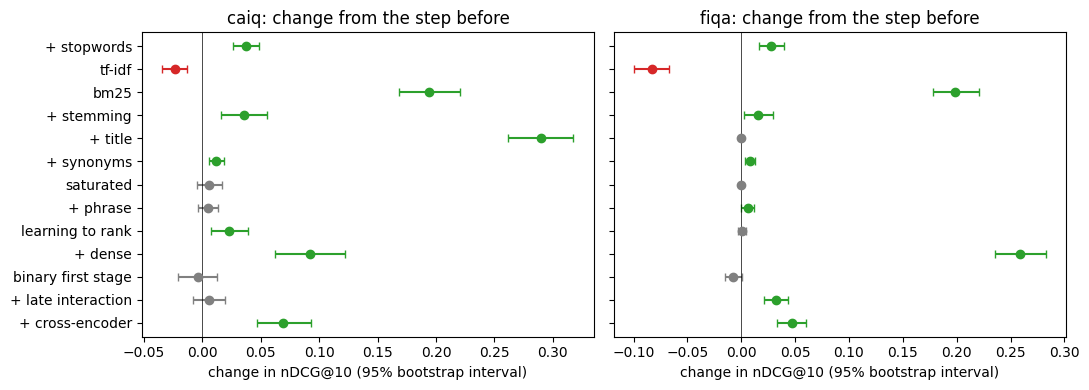

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, ds in zip(axes, DATASETS):
    steps = list(PER_Q[ds.name])
    for i, (before, step) in enumerate(zip(steps, steps[1:])):
        d = PER_Q[ds.name][step] - PER_Q[ds.name][before]  # the same questions, before and after
        lo, hi = lab.bootstrap(d)
        color = "C2" if lo > 0 else "C3" if hi < 0 else "grey"
        ax.errorbar(d.mean(), i, xerr=[[d.mean() - lo], [hi - d.mean()]], fmt="o", color=color, capsize=3)
    ax.axvline(0, color="black", lw=0.5)
    ax.set_yticks(range(len(steps) - 1), steps[1:])
    ax.set_title(f"{ds.name}: change from the step before")
    ax.set_xlabel("change in nDCG@10 (95% bootstrap interval)")
axes[0].invert_yaxis()
fig.tight_layout()

## 19. Leaderboard

The leaderboard measures your search on FiQA questions that are not in the notebook. Write a function that searches for one new question, and submit it!

In [47]:
import json, re, urllib.error, urllib.request
from concurrent.futures import ThreadPoolExecutor

LAB = json.load(open(".lab.json"))  # written by: python3 lab.py connect URL TOKEN

def post(url, key, body):
    req = urllib.request.Request(url, json.dumps(body).encode(),
                                 {"Authorization": f"Bearer {key}", "Content-Type": "application/json"})
    try:
        with urllib.request.urlopen(req, timeout=120) as r:
            return json.load(r)
    except urllib.error.HTTPError as e:
        raise RuntimeError(f"{e.code}: {e.read().decode(errors='replace')}") from None

def embed(text):
    """The question's pplx vector, from the encoder that made the documents' vectors (on your machine)."""
    return lab.embed([text])

In [48]:
DOC_BITS = {name: (d.mean(0), signs(d - d.mean(0))) for name, (d, _) in VEC.items()}

def search(ds, query, qid=None, k=5, mask=None, rerank=True):
    """The ladder for one new question: lexical + dense over the binary candidates, then Voyage on the top 20.
    qid hides what that question hides (its own answer); mask (one bool per document) searches only those documents;
    rerank=False stops before Voyage (the lab can rerank only its own datasets)."""
    one = lab.single(ds, query, qid)
    keep = np.ones(len(ds.ids), dtype=bool) if mask is None else np.asarray(mask)
    only = lambda s: np.where(keep, s, -np.inf)
    body = lab.bm25(one, ds.bodies, idf_texts=ds.title_body, analyzer=ANALYZER)
    title = lab.bm25(one, ds.titles, idf_texts=ds.title_body, analyzer=ANALYZER)
    lexical = body / (S + body) + title / (S + title) + 0.2 * (0.5 * lab.phrase(one, ds.bodies, ANALYZER) + lab.phrase(one, ds.titles, ANALYZER))
    q = embed(query)
    mean, bits = DOC_BITS[ds.name]
    n = min(20, len(ds.ids))
    cand = lab.candidates(one, [only(signs(q - mean) @ bits.T), only(body + title)], n)
    step5 = np.where(cand & keep, 4 * np.maximum(0, (q - mean) @ bits.T / np.sqrt(bits.shape[1])) + lexical, -np.inf)
    top = lab.topk(one, step5, n)
    top = top[:, np.isfinite(np.take_along_axis(step5, top, 1))[0]]
    if not rerank or top.shape[1] < 2:
        return top[0][:k]
    fused = minmax(np.take_along_axis(step5, top, 1)) + 4 * minmax(lab.rerank(one, top, "voyage-rerank-3"))
    return top[0][np.argsort(-fused[0])][:k]

def bm25_search(ds, query, qid=None, k=5):
    """Plain BM25 over the body."""
    one = lab.single(ds, query, qid)
    return lab.topk(one, lab.bm25(one, ds.bodies), k)[0]

def hits(ds, rows):
    return "\n".join(f"{n}. [doc:{ds.ids[i]}] {ds.titles[i]}\n   {ds.bodies[i][:300]}" for n, i in enumerate(rows, 1))

def read(ds, doc_id):
    i = ds.row.get(doc_id)
    return f"[doc:{doc_id}] {ds.titles[i]}\n{ds.bodies[i][:4000]}" if i is not None else f"no document {doc_id}"

In [58]:
for label, fn in (("bm25", bm25_search), ("the ladder", search)):
    print(label, lab.submit(fiqa, fn, label))

bm25 {'score': 0.0578, 'best': 0.4551, 'rank': 1, 'of': 2}


the ladder {'score': 0.455, 'best': 0.4551, 'rank': 1, 'of': 2}


## 20. A RAG agent from scratch

Search is usually just a capability among others, that we would like to expose to a language model. A search *agent* decides what to search for, reads the results and searches again until it can answer. The lab server gives you an OpenAI-compatible API with DeepSeek V4 Flash. We evaluate the agent's answers against a Python grader using the question's relevance judgments.

In [49]:
BASE_URL, API_KEY, MODEL = LAB["url"] + "/v1", LAB["token"], "deepseek-v4-flash"  # or any OpenAI-compatible provider

def chat(messages, tools=(), tool_choice="auto"):
    body = dict(model=MODEL, messages=messages, **(dict(tools=list(tools), tool_choice=tool_choice) if tools else {}))
    return post(f"{BASE_URL}/chat/completions", API_KEY, body)

reply = chat([dict(role="user", content="In one sentence: what does BM25 score?")])
print(reply["choices"][0]["message"]["content"])
print(reply["usage"])

BM25 scores the relevance of a document to a given search query by calculating the weighted frequency of query terms within the document, adjusted for document length and the rarity of those terms across the entire corpus.
{'prompt_tokens': 14, 'completion_tokens': 364, 'total_tokens': 378, 'cost': 8.568e-05, 'is_byok': False, 'prompt_tokens_details': {'cached_tokens': 0, 'cache_write_tokens': 0, 'audio_tokens': 0, 'video_tokens': 0}, 'cost_details': {'upstream_inference_cost': 8.568e-05, 'upstream_inference_prompt_cost': 1.96e-06, 'upstream_inference_completions_cost': 8.372e-05}, 'completion_tokens_details': {'reasoning_tokens': 323, 'image_tokens': 0, 'audio_tokens': 0}, 'usd': 8.6e-05}


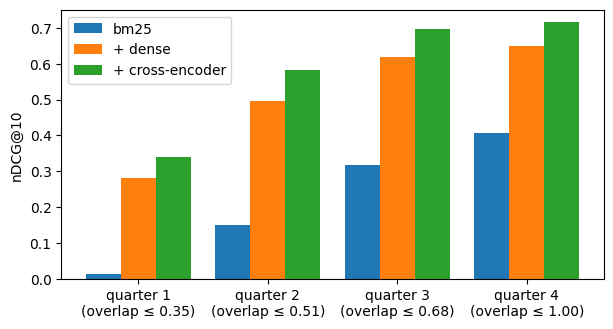

In [50]:
INDEX = lab.index(fiqa.bodies)

def overlap(ds, qid):
    """How much of the question's wording (weighted by idf) its best relevant post contains."""
    weight = {t: INDEX.idf[INDEX.vocab[t]] for t in set(lab.tokenize(ds.queries[qid])) if t in INDEX.vocab}
    total = sum(weight.values()) or 1.0
    posts = [set(lab.tokenize(ds.bodies[ds.row[d]])) for d, g in ds.qrels[qid].items() if g > 0 and d in ds.row]
    return max((sum(w for t, w in weight.items() if t in p) / total for p in posts), default=0.0)

OVERLAP = np.array([overlap(fiqa, q) for q in fiqa.qids])
quarter = np.digitize(OVERLAP, np.quantile(OVERLAP, [0.25, 0.5, 0.75]))
fig, ax = plt.subplots(figsize=(7, 3.5))
for k, step in enumerate(("bm25", "+ dense", "+ cross-encoder")):
    ax.bar(np.arange(4) + 0.27 * (k - 1), [np.mean([runs["fiqa"][step][q] for q, b in zip(fiqa.qids, quarter) if b == j])
                                            for j in range(4)], 0.27, label=step)
ax.set_xticks(range(4), [f"quarter {j + 1}\n(overlap ≤ {OVERLAP[quarter == j].max():.2f})" for j in range(4)])
ax.set_ylabel("nDCG@10")
ax.legend()

In [51]:
HARD = sorted(np.random.default_rng(0).choice([q for q, b in zip(fiqa.qids, quarter) if b == 0], 15, replace=False))
qid = HARD[0]
print(fiqa.queries[qid], "\n")
for name, fn in (("bm25_search", bm25_search), ("search", search)):
    found = fn(fiqa, fiqa.queries[qid], qid)
    print(f"{name}: relevant {[fiqa.qrels[qid].get(fiqa.ids[i], 0) for i in found]}")
    print(hits(fiqa, found[:2]), "\n")


Understanding the T + 3 settlement days rule 

bm25_search: relevant [0, 0, 0, 0, 0]
1. [doc:179520] 
   Your question is unanswerable as you haven't provided enough information. I.e. If those shares cost $1000 and you have $50000 ( or any number above $1000) of cash available in the account then you can't possibly free ride. I think your understanding of the free ride rule is incorrect. Basically what
2. [doc:370635] 
   During the settlement period, the buyer transfers payment to the seller and the seller transfers ownership to the buyer. This is really a holdover from the days when so much of stock trading was done by individual human traders, and computers were still not a huge part of the operation.  Back then,  



Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

search: relevant [0, 0, 0, 0, 0]
1. [doc:156029] 
   That is the standard set by most securities exchanges: T+3 : trades complete three days after the bargain has been struck.
2. [doc:176717] 
   "The T+3 ""rule"" relates only to accounting and not to trading.  It does not prevent you from day trading.  It simply means that the postings in you cash account will not appear until three business days after you have executed a trade.  When you execute a trade and the order has been filled, you h 



In [52]:
SYSTEM = ("You answer a financial question using the forum posts in the corpus. Answer concisely and practically. If "
          "the posts do not answer the question, say so. Search with a few focused queries, read the most promising posts, "
          "and cite every post you rely on as [doc:ID].")
TOOLS = [
    dict(type="function", function=dict(name="search", description="Search the forum posts. Returns the 5 best posts with a snippet each.",
                                        parameters=dict(type="object", properties=dict(query=dict(type="string")), required=["query"]))),
    dict(type="function", function=dict(name="read", description="Read one post in full.",
                                        parameters=dict(type="object", properties=dict(doc_id=dict(type="string")), required=["doc_id"]))),
]

def agent(ds, qid, search_with, budget=2, verbose=False):
    """The model answers question qid with up to `budget` turns of tool calls, then one turn with tools off."""
    messages = [dict(role="system", content=SYSTEM), dict(role="user", content=ds.queries[qid])]
    seen, searches, usd = set(), 0, 0.0
    for turn in range(budget + 1):
        if turn == budget:
            messages.append(dict(role="user", content="Tools are off now. Write your final answer from what you have read."))
        reply = chat(messages, TOOLS, "auto" if turn < budget else "none")
        usd += reply["usage"].get("usd", 0)
        msg = reply["choices"][0]["message"]
        messages.append(msg)
        for call in msg.get("tool_calls") or []:
            name, args = call["function"]["name"], json.loads(call["function"]["arguments"])
            if verbose:
                print(f"{name}({args})")
            if name == "search":
                rows = search_with(ds, args["query"], qid)
                seen |= {ds.ids[i] for i in rows}
                searches += 1
                out = hits(ds, rows)
            else:
                out = read(ds, args["doc_id"])
            messages.append(dict(role="tool", tool_call_id=call["id"], content=out))
        if not msg.get("tool_calls"):
            break
    return outcome(ds, qid, msg["content"] or "", seen, searches, usd)

def rag(ds, qid, search_with):
    """Classic RAG: one search with the question itself, the top 5 in the prompt, one answer."""
    rows = search_with(ds, ds.queries[qid], qid)
    reply = chat([dict(role="system", content=SYSTEM),
                  dict(role="user", content=f"{ds.queries[qid]}\n\nSearch results:\n{hits(ds, rows)}")])
    return outcome(ds, qid, reply["choices"][0]["message"]["content"] or "", {ds.ids[i] for i in rows}, 1,
                   reply["usage"].get("usd", 0))

def outcome(ds, qid, answer, seen, searches, usd):
    """The run's facts, checked against the question's graded posts: score is 1 when the answer cites a relevant post."""
    relevant = lambda d: ds.qrels[qid].get(d, 0) > 0
    cited = set(re.findall(r"\[doc:([^\]]+)\]", answer))
    return dict(answer=answer, searches=searches, usd=usd, seen_relevant=any(map(relevant, seen)),
                cited=len(cited), cited_relevant=sum(map(relevant, cited)), score=float(any(map(relevant, cited))))


In [63]:
run = agent(fiqa, qid, search, verbose=True)
print("\n" + run["answer"])
print("\ncites a relevant post:", bool(run["score"]))


search({'query': 'T+3 settlement days rule'})


search({'query': 'settlement period trade plus 3 days'})


read({'doc_id': '226984'})
read({'doc_id': '327080'})
read({'doc_id': '156029'})
read({'doc_id': '370635'})



## Understanding the T+3 Settlement Rule

**What it is:** Under T+3 settlement, a trade executed on "trade date" (T) is considered complete three **trading days** later — the settlement date. On that date, the buyer actually pays and the seller actually transfers ownership [doc:156029][doc:226984]. In short: "trades complete three days after the bargain has been struck" [doc:156029].

**Why it exists:** The settlement window gives the exchanges, clearing houses, and brokers time to tally up how many shares and how many dollars need to be moved between all counterparties, and then to actually move them [doc:226984]. It's a holdover from the paper-ticket era (when it was even longer — five days); technology now makes the actual transfer fast, so the period is largely used to verify trades before settling [doc:370635].

**Key practical implications:**

- **Cash accounts:** You must wait until the T+3 settlement date before the funds from a sale are available to make your next trade [doc:

In [64]:

with ThreadPoolExecutor(8) as pool:
    RUNS = {(method.__name__, fn.__name__): list(pool.map(lambda q, m=method, f=fn: m(fiqa, q, f), HARD))
            for method in (rag, agent) for fn in (bm25_search, search)}

print(f"{'':24s}{'cites relevant':>15s}{'searches':>10s}{'relevant seen':>15s}{'cited relevant':>16s}{'cost':>8s}")
for (method, fn), rs in RUNS.items():
    cited = sum(r["cited"] for r in rs)
    print(f"{method + ', ' + fn:24s}{np.mean([r['score'] for r in rs]):15.0%}{np.mean([r['searches'] for r in rs]):10.1f}"
          f"{np.mean([r['seen_relevant'] for r in rs]):15.0%}{sum(r['cited_relevant'] for r in rs) / max(cited, 1):16.0%}"
          f"{sum(r['usd'] for r in rs):8.3f}")
for method in ("rag", "agent"):
    diff = np.array([b["score"] - a["score"] for a, b in zip(RUNS[method, "bm25_search"], RUNS[method, "search"])])
    print(f"{method}: search − bm25_search {diff.mean():+.3f} ± {1.96 * diff.std() / np.sqrt(len(diff)):.3f} (95%)")


                         cites relevant  searches  relevant seen  cited relevant    cost
rag, bm25_search                     7%       1.0             7%              3%   0.003
rag, search                         67%       1.0            67%             24%   0.004
agent, bm25_search                  13%       3.5            13%              4%   0.012
agent, search                       60%       2.2            67%             24%   0.011
rag: search − bm25_search +0.600 ± 0.248 (95%)
agent: search − bm25_search +0.467 ± 0.252 (95%)


## 21. Code mode

In code mode, the search tool is replaced by a generic coding tool that lets the agent run code and call tools from Python. This gives it powerful analysis capabilities and increases its *token efficiency*, because it no longer needs to process every result in context. Instead, the agent can perform arbitrary computations over intermediate results.

In [53]:
import builtins, io, sys, threading

class Meter(threading.local):
    calls = tokens = 0  # model calls and tokens of the run on this thread

METER = Meter()

def chat(messages, tools=(), tool_choice="auto"):
    """Section 20's chat, also counting calls and tokens in METER."""
    body = dict(model=MODEL, messages=messages, **(dict(tools=list(tools), tool_choice=tool_choice) if tools else {}))
    reply = post(f"{BASE_URL}/chat/completions", API_KEY, body)
    METER.calls += 1
    METER.tokens += reply["usage"]["total_tokens"]
    return reply

def metered(method, *args):
    """method(*args) and its model calls and tokens."""
    METER.calls = METER.tokens = 0
    run = method(*args)
    return dict(run, calls=METER.calls, tokens=METER.tokens)

SAFE = ("len", "range", "enumerate", "sorted", "min", "max", "sum", "set", "list", "dict", "str", "int", "float", "round",
        "zip", "any", "all")
MAX_LINES, MAX_OUTPUT = 100_000, 8_000

def run_code(code, functions):
    """Runs model-written code with `functions`, print and the SAFE builtins; returns what it printed and any error.
    This is NOT a security sandbox: Python's introspection reaches everything. It keeps a well-meaning model to our
    functions and stops runaway loops after MAX_LINES lines."""
    out, lines = io.StringIO(), 0

    def print_(*args, sep=" ", end="\n"):
        out.write(sep.join(map(str, args)) + end)

    def count(frame, event, arg):
        nonlocal lines
        lines += event == "line"
        if lines > MAX_LINES:
            raise RuntimeError(f"stopped after {MAX_LINES:,} lines")
        return count

    before = sys.gettrace()
    sys.settrace(lambda frame, event, arg: count if frame.f_code.co_filename == "<python>" else None)
    try:
        exec(compile(code, "<python>", "exec"), {"__builtins__": {n: getattr(builtins, n) for n in SAFE}, "print": print_, **functions})
    except Exception as e:
        print_(f"{type(e).__name__}: {e}")
    finally:
        sys.settrace(before)
    text = out.getvalue()
    return text if len(text) <= MAX_OUTPUT else text[:MAX_OUTPUT] + f"\n[cut at {MAX_OUTPUT:,} of {len(text):,} characters]"

print(run_code("for q in ('a', 'b'):\n    print(q, len(search(q)))\nimport os", dict(search=lambda q: [q] * 3)))
print(run_code("while True:\n    pass", {}))

a 3
b 3
ImportError: __import__ not found

RuntimeError: stopped after 100,000 lines



In [54]:
CODE_SYSTEM = ("You answer a financial question using the forum posts in the corpus. Answer concisely and practically. If the "
               "posts do not answer the question, say so. Your tool runs Python: in one program you can run several searches, "
               "print what you need and read the most promising posts. Cite every post you rely on as [doc:ID].")
CODE_TOOLS = [dict(type="function", function=dict(
    name="python",
    description="Run Python code. Available: search(query, k=5) -> list of {doc_id, title, snippet}, best first; "
                "read(doc_id) -> the post's text; print. Only what you print comes back (up to 8,000 characters). No imports; "
                f"builtins: {', '.join(SAFE)}.",
    parameters=dict(type="object", properties=dict(code=dict(type="string")), required=["code"])))]
MAX_SEARCHES = 15  # per question

def code_agent(ds, qid, search_with, budget=2, verbose=False):
    """Section 20's agent with one tool, python, that calls search and read."""
    messages = [dict(role="system", content=CODE_SYSTEM), dict(role="user", content=ds.queries[qid])]
    seen, searches, usd = set(), 0, 0.0

    def search_(query, k=5):
        nonlocal searches
        if searches >= MAX_SEARCHES:
            raise RuntimeError(f"no searches left ({MAX_SEARCHES} per question)")
        searches += 1
        rows = search_with(ds, str(query), qid, k=min(int(k), 20))
        seen.update(ds.ids[i] for i in rows)
        return [dict(doc_id=ds.ids[i], title=ds.titles[i], snippet=ds.bodies[i][:300]) for i in rows]

    functions = dict(search=search_, read=lambda doc_id: read(ds, str(doc_id)))
    for turn in range(budget + 1):
        if turn == budget:
            messages.append(dict(role="user", content="Tools are off now. Write your final answer from what you have read."))
        reply = chat(messages, CODE_TOOLS, "auto" if turn < budget else "none")
        usd += reply["usage"].get("usd", 0)
        msg = reply["choices"][0]["message"]
        messages.append(msg)
        for call in msg.get("tool_calls") or []:
            code = json.loads(call["function"]["arguments"]).get("code", "")
            out = run_code(code, functions)
            if verbose:
                print(f"--- code\n{code}\n--- output\n{out[:1500]}{' […]' if len(out) > 1500 else ''}")
            messages.append(dict(role="tool", tool_call_id=call["id"], content=out))
        if not msg.get("tool_calls"):
            break
    return outcome(ds, qid, msg["content"] or "", seen, searches, usd)

In [67]:
run = code_agent(fiqa, HARD[1], search, verbose=True)
print(f"\n{fiqa.queries[HARD[1]]}\n\n{run['answer']}")
print("\ncites a relevant post:", bool(run["score"]))

--- code
res = search("Walmart expired food accounting", k=10)
for r in res:
    print(r['doc_id'], "|", r['title'], "|", r['snippet'])
print("----")
res2 = search("Walmart inventory shrinkage spoilage accounting", k=10)
for r in res2:
    print(r['doc_id'], "|", r['title'], "|", r['snippet'])

--- output
191649 |  | "Any business, like any household, has items that are wasted. Unlike a household, a business does keep track of all items that are unsellable. Depending on the reason for the item being unsellable they are accounted for differently. Items that can be returned to the manufacturer are done so, and the
599998 |  | "Your argument comes down to ""he is presumed guilty until proven innocent"", a common injustice found in many authoritarian dictatorships and theocracies throughout history. Your argument seems based on the assumption that M. Armstrong is guilty without a requirement for any evidence that he did an
574840 |  | Are you sure these farmers sell straight to wall mart? 

--- code
print(read("191649"))
print("=====")
print(read("574840"))
--- output
[doc:191649] 
"Any business, like any household, has items that are wasted. Unlike a household, a business does keep track of all items that are unsellable. Depending on the reason for the item being unsellable they are accounted for differently. Items that can be returned to the manufacturer are done so, and the business is given credit for that item. For the business the time spent processing, stocking and restocking that item, plus any time spent handling a return for that customer is harder to track. If they see the percentage of bad items is too large compared to sales they will want to address this with the manufacturer. Items that are spoiled by the business, which will include spoiled food items, will also be tracked. They will examine their choice of products, their procedures for those products and the quantities produced to try an minimize the spoilage. They don't just throw the items away, they k


How does Walmart account their expired food

Based on the forum posts available, here's how expired/unsellable food is handled in grocery retail accounting (the posts describe this in general retail terms; none of them give Walmart's specific 10-K line items):

**From [doc:191649]** – Unsellable items are accounted for depending on the reason:

- **Returnable to the manufacturer:** returned, and the retailer receives a credit for that item. If spoilage/waste gets too high relative to sales, the retailer pushes the manufacturer to address it.
- **Spoiled by the business (e.g., food past its "sell-by" date):** these are tracked precisely — the items are **scanned into the computer** so the exact items and their value are recorded when disposed.
- **Recovering value:** before disposal, stores may try to "reduce for quick sale" (markdowns), transform product (e.g., bread into bread pudding), or **donate to charity/food kitchens** — all of which is also tracked.
- **Net losses** not recove

In [68]:
with ThreadPoolExecutor(8) as pool:
    CODE_RUNS = {m.__name__: list(pool.map(lambda q, m=m: metered(m, fiqa, q, search), HARD)) for m in (agent, code_agent)}
print(f"{'':12s}{'cites relevant':>15s}{'searches':>10s}{'model calls':>13s}{'tokens':>9s}{'cost':>8s}")
for name, rs in CODE_RUNS.items():
    print(f"{name:12s}{np.mean([r['score'] for r in rs]):15.0%}{np.mean([r['searches'] for r in rs]):10.1f}"
          f"{np.mean([r['calls'] for r in rs]):13.1f}{np.mean([r['tokens'] for r in rs]):9,.0f}{sum(r['usd'] for r in rs):8.3f}")
diff = np.array([b["score"] - a["score"] for a, b in zip(CODE_RUNS["agent"], CODE_RUNS["code_agent"])])
lo, hi = lab.bootstrap(diff)
print(f"\ncode_agent − agent: {diff.mean():+.3f} (95% interval {lo:+.3f} to {hi:+.3f}) over {len(diff)} questions")

             cites relevant  searches  model calls   tokens    cost
agent                   67%       2.2          3.0    4,976   0.012
code_agent              53%       3.2          3.0    4,844   0.011

code_agent − agent: -0.133 (95% interval -0.333 to +0.000) over 15 questions


## 22. Filters, sorting and counts

Many questions are not about meaning but about attributes in documents. Consider a dataset of documents in a customer relationship management (CRM) system, the attributes might include country, stage, owner, dates. Relevance ranking alone cannot answer "open deals over 50k in Finland"; that needs *structured search* (filters, sorting and counts over the fields) combined with text search over attached notes on the deals.

We introduce a fake CRM dataset of 600 deals. The agent still needs to search over attributes and values (*attribute search*), for which it leverages the same ranking function we developed earlier. The agent leaderboard scores your CRM agent on 16 questions on the CRM dataset.

In [55]:
import operator
from collections import Counter

DEALS = lab.crm(n=600, seed=0)
CATEGORIES = lab.CATEGORIES
NUMBERS = ("amount_eur", "annual_revenue_eur", "employees", "probability")
print(f"{len(DEALS)} deals; fields: {', '.join(DEALS[0])}\n")
for d in DEALS[:3]:
    print(json.dumps(d, ensure_ascii=False), "\n")

600 deals; fields: deal_id, company, industry, country, stage, amount_eur, annual_revenue_eur, employees, probability, close_date, last_activity_date, owner, product, lead_source, notes

{"deal_id": "D0001", "company": "Elm Motors", "industry": "Construction", "country": "Denmark", "stage": "Closed won", "amount_eur": 56400.0, "annual_revenue_eur": 631880000.0, "employees": 5525, "probability": 1.0, "close_date": "2026-06-12", "last_activity_date": "2026-05-30", "owner": "Lukas Weber", "product": "Support Plus", "lead_source": "Webinar", "notes": "Elm Motors wants to consolidate reporting across its regional offices. Pipewise offered a 30% discount. Strong executive sponsor, low risk."} 

{"deal_id": "D0002", "company": "Lumen Logistics", "industry": "Media", "country": "Canada", "stage": "Closed lost", "amount_eur": 129900.0, "annual_revenue_eur": 129240000.0, "employees": 741, "probability": 0.0, "close_date": "2026-06-14", "last_activity_date": "2026-06-06", "owner": "Anna Schmidt",

In [56]:
VECS = lab.embeddings()  # precomputed with the data; anything else is embedded here

def embed_many(texts):
    """Unit pplx vectors of texts; each text is embedded once."""
    new = list(dict.fromkeys(t for t in texts if t not in VECS))
    VECS.update(zip(new, lab.embed(new)))
    return np.stack([VECS[t] for t in texts])

def index(name):
    """A dataset that `search` can search (lab.documents(name)): the documents and their pplx vectors, no questions."""
    ids, titles, bodies = lab.documents(name)
    d = embed_many([f"{t}\n{x}" for t, x in zip(titles, bodies)])
    VEC[name], DOC_BITS[name] = (d, None), (d.mean(0), signs(d - d.mean(0)))
    return lab.Dataset(name, list(ids), list(titles), list(bodies), {}, {}, {})

CRM = index("crm")

def key(field, x):
    return float(x) if field in NUMBERS else str(x).lower()  # dates are YYYY-MM-DD, so they compare as text

def matches(deal, field, want):
    """want: a value, a list of values (any of them), or {"min": x, "max": y}, both ends included; text ignores case."""
    v = key(field, deal[field])
    if isinstance(want, dict):
        return all(op(v, key(field, want[end])) for end, op in (("min", operator.ge), ("max", operator.le)) if end in want)
    return v in {key(field, w) for w in (want if isinstance(want, list) else [want])}

def search_crm(query="", filters=None, sort_by=None, descending=True, fields=None, limit=10, group_by=None):
    """`search` on the deals, plus what their attributes allow: filters narrow the deals it searches, sort_by orders
    the results by a number or date, fields picks what comes back, group_by counts the deals per value. total is the
    number of deals that pass the filters; with a query, the results are the best matches among them."""
    filters = filters or {}
    unknown = [f for f in [*filters, sort_by, group_by, *(fields or [])] if f is not None and f not in DEALS[0]]
    if unknown:
        return dict(error=f"unknown fields {unknown}; the fields are {list(DEALS[0])}")
    mask = np.array([all(matches(d, f, w) for f, w in filters.items()) for d in DEALS])
    rows = list(search(CRM, query, k=50, mask=mask, rerank=False)) if query.strip() else list(np.flatnonzero(mask))
    if sort_by:
        rows.sort(key=lambda i: key(sort_by, DEALS[i][sort_by]), reverse=descending)
    keep = ["deal_id", *(fields or ["company", "industry", "country", "stage", "amount_eur", "owner"])]
    out = dict(total=int(mask.sum()), deals=[{f: DEALS[i][f] for f in keep} for i in rows[:min(int(limit), 50)]])
    if group_by:
        out["counts"] = dict(Counter(DEALS[i][group_by] for i in np.flatnonzero(mask)).most_common())
    return out

print(hits(CRM, search(CRM, "worried about security, budget frozen", rerank=False)[:3]), "\n")
print(search_crm(filters={"country": ["Finland", "Sweden"], "amount_eur": {"min": 20000}}, sort_by="amount_eur",
                 fields=["company", "country", "stage", "amount_eur"], limit=3, group_by="stage"))

1. [doc:D0387] Zenith Group
   Zenith Group is tightening data security after a breach. Budget freeze until the second quarter. industry: Education; country: Finland; stage: Contract sent; amount eur: 26400.0; annual revenue eur: 17390000.0; employees: 113; probability: 0.9; close date: 2026-12-24; last activity date: 2026-10-04;
2. [doc:D0486] Fjord Systems
   Fjord Systems wants to automate support ticket routing. Currently uses Pipewise and is unhappy with the pricing. Budget freeze until the second quarter. industry: Healthcare; country: United Kingdom; stage: Negotiation; amount eur: 108600.0; annual revenue eur: 1006650000.0; employees: 7640; probabi
3. [doc:D0278] Boreal Capital
   Boreal Capital needs an integration with SAP. Budget freeze until the second quarter. industry: Public sector; country: United Kingdom; stage: Closed won; amount eur: 50200.0; annual revenue eur: 20700000.0; employees: 233; probability: 1.0; close date: 2026-06-01; last activity date: 2026-05-28; ow 


In [57]:
VALUE_DS = index("crm-values")
VALUES = [tuple(i.split("=", 1)) for i in VALUE_DS.ids]
FIELD_DS = index("crm-fields")

def find_values(text, field=None, k=10):
    """The values of the category fields that best match text, e.g. "fintech" -> industry "Financial services"."""
    mask = None if field is None else np.array([f == field for f, _ in VALUES])
    return [dict(field=VALUES[i][0], value=VALUES[i][1]) for i in search(VALUE_DS, text, k=int(k), mask=mask, rerank=False)]

def find_fields(text, k=3):
    """The number and date fields that best match text, e.g. "biggest" -> amount_eur."""
    return [dict(field=FIELD_DS.ids[i], about=FIELD_DS.bodies[i]) for i in search(FIELD_DS, text, k=int(k), rerank=False)]

for text in ("fintech", "the Nordics", "late stage", "Maria", "car makers"):
    print(f"{text!r:14} {[v['value'] for v in find_values(text, k=5)]}")
for text in ("biggest", "gone quiet", "headcount", "about to close"):
    print(f"{text!r:16} {[f['field'] for f in find_fields(text)]}")

'fintech'      ['Financial services', 'Education', 'Insurance', 'Analytics Suite', 'Support Plus']


'the Nordics'  ['Norway', 'Iceland', 'Denmark', 'Finland', 'Sweden']
'late stage'   ['Contract sent', 'Negotiation', 'Qualification', 'Closed lost', 'Discovery']


'Maria'        ['Maria Virtanen', 'Sofia Rossi', 'Anna Schmidt', 'Emma Johansson', 'Olivia Brown']


'car makers'   ['Automotive', 'Mikko Laine', 'Discovery', 'Maria Virtanen', 'Construction']
'biggest'        ['amount_eur', 'probability', 'annual_revenue_eur']


'gone quiet'     ['last_activity_date', 'employees', 'probability']


'headcount'      ['employees', 'amount_eur', 'annual_revenue_eur']
'about to close' ['close_date', 'probability', 'annual_revenue_eur']


In [58]:
CRM_SYSTEM = (f"You answer questions about our sales deals with the CRM search. Today is {lab.CRM_TODAY}. A deal is open "
              "until it is won or lost. End your answer with one line: DEALS: the comma-separated ids of the deals that answer "
              "the question (DEALS: none if there are none).")

def tool(name, description, required=(), **params):
    return dict(type="function", function=dict(name=name, description=description,
                                               parameters=dict(type="object", properties=params, required=list(required))))

PLAIN_SEARCH = tool("search", "Search the CRM's deals. Returns the 5 best deals with a snippet each.", ["query"],
                    query=dict(type="string"))
READ_DEAL = tool("read", "Read one deal in full.", ["doc_id"], doc_id=dict(type="string"))
ATTR_SEARCH = tool(
    "search",
    "Search the CRM's deals. Fields: deal_id, company, notes (text); industry, country, stage, owner, product, lead_source "
    "(categories); amount_eur, annual_revenue_eur, employees, probability (numbers); close_date, last_activity_date "
    "(dates, YYYY-MM-DD). Returns the number of deals passing the filters and the first `limit` of them.",
    query=dict(type="string", description="What to look for in the deals; empty: every deal that passes the filters."),
    filters=dict(type="object", description='{field: value | [values] | {"min": x, "max": y}}; exact values, any case; '
                                            "min and max are inclusive."),
    sort_by=dict(type="string", description="A number or date field."), descending=dict(type="boolean"),
    fields=dict(type="array", items=dict(type="string"), description="The fields to return."),
    limit=dict(type="integer", description="At most 50; default 10."),
    group_by=dict(type="string", description="A category field: also return the number of matching deals per value."))
FIND_VALUES = tool("find_values", "Find the exact values of the category fields (industry, country, stage, owner, product, "
                   "lead_source) that match a word or phrase.", ["text"], text=dict(type="string"),
                   field=dict(type="string", description="Only this field's values."), k=dict(type="integer"))
FIND_FIELDS = tool("find_fields", "Find the number and date fields that match a property, e.g. 'size of the deal'.", ["text"],
                   text=dict(type="string"), k=dict(type="integer"))
PLAIN = dict(search=lambda query: hits(CRM, search(CRM, query, rerank=False)), read=lambda doc_id: read(CRM, doc_id))
ATTR = dict(search=search_crm, find_values=find_values, find_fields=find_fields)

def crm_agent(question, tools, functions, budget=5, verbose=False):
    """The model answers with up to `budget` turns of tool calls, then one turn with tools off. It lists its deals in
    the last line, so it is judged on what it says it found."""
    messages = [dict(role="system", content=CRM_SYSTEM), dict(role="user", content=question)]
    usd, calls = 0.0, []
    for turn in range(budget + 1):
        if turn == budget:
            messages.append(dict(role="user", content="Tools are off now. Write your final answer from what you have found."))
        reply = chat(messages, tools, "auto" if turn < budget else "none")
        usd += reply["usage"].get("usd", 0)
        msg = reply["choices"][0]["message"]
        messages.append(msg)
        for call in msg.get("tool_calls") or []:
            name = call["function"]["name"]
            try:
                args = json.loads(call["function"]["arguments"])
                out = functions[name](**args)
            except (KeyError, TypeError, ValueError, RuntimeError) as e:  # the model sees the error and can retry
                out = dict(error=f"{type(e).__name__}: {e}")
            calls.append(name)
            if verbose:
                print(f"{name}({call['function']['arguments']})\n  -> {str(out)[:400]}")
            messages.append(dict(role="tool", tool_call_id=call["id"], content=out if isinstance(out, str) else json.dumps(out, ensure_ascii=False)))
        if not msg.get("tool_calls"):
            break
    answer = msg["content"] or ""
    last = re.findall(r"^\W*DEALS:(.*)$", answer, re.M)
    return dict(answer=answer, deals=set(re.findall(r"D\d{4}", last[-1])) if last else set(), calls=calls, usd=usd)

In [59]:
NORDICS = ["Norway", "Sweden", "Denmark", "Finland", "Iceland"]
OPEN = [s for s in lab.STAGES if not s.startswith("Closed")]
QUESTIONS = [  # (question, the search_crm call that answers it)
    ("Fintech deals in the Nordics that are in negotiation or have a contract out.",
     dict(filters=dict(industry="Financial services", country=NORDICS, stage=["Negotiation", "Contract sent"]))),
    ("Which 5 of Maria's open deals have gone quiet the longest?",
     dict(filters=dict(owner="Maria Virtanen", stage=OPEN), sort_by="last_activity_date", descending=False, limit=5)),
    ("Which deals did we lose in Germany this year?",
     dict(filters=dict(country="Germany", stage="Closed lost", close_date=dict(min="2026-01-01")))),
    ("Pharma companies with more than 2,000 staff that are still in our pipeline.",
     dict(filters=dict(industry="Pharmaceuticals", employees=dict(min=2001), stage=OPEN))),
    ("The five largest deals for our AI product in the DACH countries.",
     dict(filters=dict(product="AI Assistant", country=["Germany", "Austria", "Switzerland"]), sort_by="amount_eur", limit=5)),
    ("Jonas's deals over 30k that haven't got past qualification yet.",
     dict(filters=dict(owner="Jonas Berg", amount_eur=dict(min=30000), stage=["Prospecting", "Qualification"]))),
    ("Which of Anna's deals close in the first quarter of 2027?",
     dict(filters=dict(owner="Anna Schmidt", close_date=dict(min="2027-01-01", max="2027-03-31")))),
    ("Open energy deals where nobody has talked to the customer since the start of September.",
     dict(filters=dict(industry="Energy", stage=OPEN, last_activity_date=dict(max="2026-08-31")))),
    ("Which banks and insurers in France have we had deals with?",
     dict(filters=dict(industry=["Financial services", "Insurance"], country="France"))),
    ("Small companies (under 50 people) we won in the Benelux.",
     dict(filters=dict(employees=dict(max=49), stage="Closed won", country=["Netherlands", "Belgium", "Luxembourg"]))),
]
GOLD = []
for q, call in QUESTIONS:
    r = search_crm(**{"limit": 50, **call})
    assert "limit" in call or r["total"] <= 50
    GOLD.append({d["deal_id"] for d in r["deals"]})
print("gold deals per question:", [len(g) for g in GOLD])

gold deals per question: [1, 5, 9, 3, 5, 6, 11, 3, 2, 2]


In [74]:
CONDITIONS = {"search": ([PLAIN_SEARCH, READ_DEAL], PLAIN), "search + attributes": ([ATTR_SEARCH], ATTR),
              "+ value and field search": ([ATTR_SEARCH, FIND_VALUES, FIND_FIELDS], ATTR)}
with ThreadPoolExecutor(8) as pool:
    CRM_RUNS = {c: list(pool.map(lambda q, t=t, f=f: crm_agent(q, t, f), [q for q, _ in QUESTIONS]))
                for c, (t, f) in CONDITIONS.items()}
EXACT = {c: np.array([r["deals"] == g for r, g in zip(rs, GOLD)], dtype=float) for c, rs in CRM_RUNS.items()}
JACCARD = {c: np.array([len(r["deals"] & g) / max(len(r["deals"] | g), 1) for r, g in zip(rs, GOLD)]) for c, rs in CRM_RUNS.items()}
print(f"{'':28s}{'exact set':>11s}{'Jaccard':>9s}{'tool calls':>12s}{'cost':>8s}")
for c, rs in CRM_RUNS.items():
    lo, hi = lab.bootstrap(JACCARD[c])
    print(f"{c:28s}{EXACT[c].mean():11.0%}{JACCARD[c].mean():9.2f}{np.mean([len(r['calls']) for r in rs]):12.1f}"
          f"{sum(r['usd'] for r in rs):8.3f}   Jaccard 95% interval {lo:.2f} to {hi:.2f}")

                              exact set  Jaccard  tool calls    cost
search                              20%     0.39        13.5   0.034   Jaccard 95% interval 0.19 to 0.61
search + attributes                 80%     0.80         5.1   0.019   Jaccard 95% interval 0.50 to 1.00
+ value and field search            90%     0.99         5.4   0.013   Jaccard 95% interval 0.96 to 1.00


In [75]:
print("exact set:", " | ".join(CONDITIONS))
for q, *rs in zip([q for q, _ in QUESTIONS], *CRM_RUNS.values()):
    g = GOLD[[x for x, _ in QUESTIONS].index(q)]
    print("  ".join("✓" if r["deals"] == g else "✗" for r in rs), q)

exact set: search | search + attributes | + value and field search
✓  ✗  ✓ Fintech deals in the Nordics that are in negotiation or have a contract out.
✗  ✓  ✓ Which 5 of Maria's open deals have gone quiet the longest?
✗  ✓  ✓ Which deals did we lose in Germany this year?
✗  ✗  ✓ Pharma companies with more than 2,000 staff that are still in our pipeline.
✓  ✓  ✓ The five largest deals for our AI product in the DACH countries.
✗  ✓  ✗ Jonas's deals over 30k that haven't got past qualification yet.
✗  ✓  ✓ Which of Anna's deals close in the first quarter of 2027?
✗  ✓  ✓ Open energy deals where nobody has talked to the customer since the start of September.
✗  ✓  ✓ Which banks and insurers in France have we had deals with?
✗  ✓  ✓ Small companies (under 50 people) we won in the Benelux.


In [76]:
run = crm_agent("How are our customers in Norway doing?", [ATTR_SEARCH, FIND_VALUES, FIND_FIELDS], ATTR, verbose=True)
print("\n" + run["answer"])
print(f"\ncost {run['usd']:.4f}")

search({"filters": "", "fields": ["deal_id", "company", "stage", "amount_eur", "annual_revenue_eur", "employees", "last_activity_date", "close_date", "owner", "product"], "limit": 50})
  -> {'total': 600, 'deals': [{'deal_id': 'D0001', 'company': 'Elm Motors', 'stage': 'Closed won', 'amount_eur': 56400.0, 'annual_revenue_eur': 631880000.0, 'employees': 5525, 'last_activity_date': '2026-05-30', 'close_date': '2026-06-12', 'owner': 'Lukas Weber', 'product': 'Support Plus'}, {'deal_id': 'D0002', 'company': 'Lumen Logistics', 'stage': 'Closed lost', 'amount_eur': 129900.0, 'annual_revenu


find_values({"text": "Norway", "field": "country"})
  -> [{'field': 'country', 'value': 'Norway'}, {'field': 'country', 'value': 'Iceland'}, {'field': 'country', 'value': 'Finland'}, {'field': 'country', 'value': 'Netherlands'}, {'field': 'country', 'value': 'Switzerland'}, {'field': 'country', 'value': 'Denmark'}, {'field': 'country', 'value': 'Spain'}, {'field': 'country', 'value': 'Portugal'}, {'field': 'country', 'value': 'Italy'}, {'field': 'countr


search({"filters": {"country": "Norway"}, "fields": ["deal_id", "company", "stage", "amount_eur", "annual_revenue_eur", "employees", "last_activity_date", "close_date", "owner", "product"], "limit": 50})
  -> {'total': 49, 'deals': [{'deal_id': 'D0017', 'company': 'Iris Labs', 'stage': 'Closed won', 'amount_eur': 12600.0, 'annual_revenue_eur': 22670000.0, 'employees': 144, 'last_activity_date': '2026-07-25', 'close_date': '2026-07-25', 'owner': 'Emma Johansson', 'product': 'Integration Hub'}, {'deal_id': 'D0023', 'company': 'Falcon Holdings', 'stage': 'Proposal', 'amount_eur': 64500.0, 'annual_revenue_



Here's how our Norway book of business looks (49 deals in total):

**Won business (13):** D0017, D0049, D0068, D0127, D0293, D0295, D0318, D0362, D0403, D0423, D0445, D0531, D0596 — solid base of closed wins, mostly small-to-mid contracts ranging from ~€3.9k to ~€70.8k.

**Lost business (7):** D0108, D0143, D0211, D0224, D0467, D0529, D0591 — a few notable losses (D0529 Cedar Systems at €76.5k, D0108 Falcon Health at €42k, D0591 Alder Works at €40.7k).

**Open pipeline (29):**
- Prospecting (3): D0261, D0275, D0506 — D0506 Fjord Solutions is a large one (€233.9k, 10k+ employees)
- Qualification (7): D0094, D0220, D0341, D0532, D0535, D0562, D0569 — D0535 Cedar Bank (€165.9k) and D0562 Harbor Motors (€77.7k) are the biggest
- Discovery (5): D0241, D0331, D0367, D0589, D0600
- Proposal (9): D0023, D0026, D0182, D0274, D0396, D0397, D0463, D0504, D0546
- Contract sent (3): D0040, D0152, D0363
- Negotiation (2): D0062, D0495

**Bottom line:** Norway is a healthy, active market. More than 

In [77]:
# the agent leaderboard: 16 harder CRM questions; the lab scores the share answered exactly
print(lab.submit_agent(lambda q: crm_agent(q, [ATTR_SEARCH, FIND_VALUES, FIND_FIELDS], ATTR)["deals"],
                       "search + attributes + value and field search"))

{'score': 0.875, 'best': 0.875, 'rank': 1, 'of': 2}


## 23. Tool search

Production agents require a large number of tools to do their job. An agent with 60 tools cannot read every tool description in each request: the descriptions and parameter schemas would waste space in the agent's input context, reducing its context efficiency and answer quality.

Similar to attribute search, we can consider the agent's set of tools as documents to retrieve, and use our previously developed ranking techniques to retrieve and rank over tool names, descriptions and schemas to find the right tools for each task.

bm25      recall@5 0.80  nDCG@5 0.70
dense     recall@5 0.95  nDCG@5 0.84
ladder    recall@5 0.97  nDCG@5 0.80


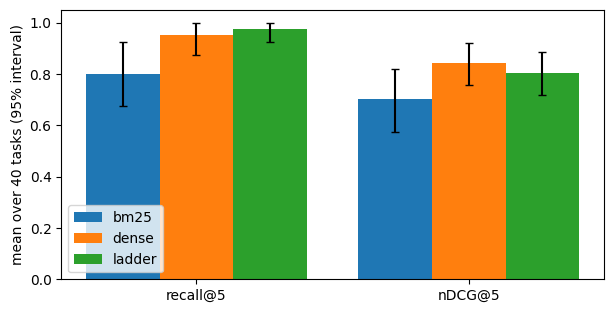

In [60]:
CATALOG = lab.tool_catalog()
TOOL_NAMES = [t["function"]["name"] for t in CATALOG]
TOOLS_DS = index("tools")
TASKS = [task for task, _ in lab.TOOL_TASKS]
embed_many(TASKS)  # one batch instead of one per task

def find_tools(how, query, k=5):
    """The k best tools for query: bm25 alone, dense alone, or the ladder's first stage (search without reranking)."""
    if how == "bm25":
        return bm25_search(TOOLS_DS, query, k=k)
    if how == "dense":
        return np.argsort(-(VEC["tools"][0] @ embed_many([query])[0]), kind="stable")[:k]
    return search(TOOLS_DS, query, k=k, rerank=False)

def rank_of(rows, i):
    return list(rows).index(i) + 1 if i in list(rows) else 99

RANKS = {how: np.array([rank_of(find_tools(how, task, 20), TOOL_NAMES.index(wanted)) for task, wanted in lab.TOOL_TASKS])
         for how in ("bm25", "dense", "ladder")}
METRICS = {how: {"recall@5": (r <= 5).astype(float), "nDCG@5": np.where(r <= 5, 1 / np.log2(r + 1), 0.0)}
           for how, r in RANKS.items()}  # one relevant tool: its gain at rank r is 1 / log2(r + 1)
fig, ax = plt.subplots(figsize=(7, 3.5))
for k, (how, m) in enumerate(METRICS.items()):
    means = [x.mean() for x in m.values()]
    lo, hi = np.array([lab.bootstrap(x) for x in m.values()]).T
    ax.bar(np.arange(2) + 0.27 * (k - 1), means, 0.27, yerr=[np.array(means) - lo, hi - np.array(means)], capsize=3, label=how)
    print(f"{how:8s}" + "".join(f"  {name} {x.mean():.2f}" for name, x in m.items()))
ax.set_xticks(range(2), list(METRICS["bm25"]))
ax.set_ylabel(f"mean over {len(TASKS)} tasks (95% interval)")
ax.set_ylim(0, 1.05)
ax.legend()

In [61]:
print("the ladder's misses:")
for (task, wanted), r in zip(lab.TOOL_TASKS, RANKS["ladder"]):
    if r > 5:
        print(f"  {task}\n    wanted {wanted} (rank {r}); top 3: {[TOOL_NAMES[i] for i in find_tools('ladder', task, 3)]}")

the ladder's misses:
  Let Mikko know privately that the build is green.
    wanted send_direct_message (rank 15); top 3: ['rollback_deployment', 'pin_chat_message', 'restart_service']


In [80]:
TOOL_SYSTEM = ("You are a workplace assistant with a catalog of about 60 tools. You start with search_tools only: describe what "
               "you need, and the tools it finds become callable on your next turn. Do the request with the right tool; do not "
               "ask questions, fill in reasonable values for missing details.")
SEARCH_TOOLS = tool("search_tools", "Find tools in the catalog by describing what you want to do. Returns the 5 best tools; "
                    "they become callable on your next turn.", ["query"], query=dict(type="string"))
SCHEMA = dict(zip(TOOL_NAMES, CATALOG))
BEST = max(METRICS, key=lambda how: METRICS[how]["nDCG@5"].mean())

def tool_agent(task, budget=4, verbose=False):
    """The model starts with search_tools (BEST's ranking); each turn's searches replace the tools offered before (the
    lab allows 8 per call). The catalog's tools do nothing and answer {"ok": true}."""
    messages = [dict(role="system", content=TOOL_SYSTEM), dict(role="user", content=task)]
    offered, called, searches, usd = [], [], 0, 0.0
    for turn in range(budget):
        reply = chat(messages, [SEARCH_TOOLS, *offered])
        usd += reply["usage"].get("usd", 0)
        msg = reply["choices"][0]["message"]
        messages.append(msg)
        found = []
        for call in msg.get("tool_calls") or []:
            name, args = call["function"]["name"], json.loads(call["function"]["arguments"])
            if name == "search_tools":
                searches += 1
                found += [TOOL_NAMES[i] for i in find_tools(BEST, args["query"])]
                out = json.dumps([SCHEMA[n]["function"] for n in found[-5:]])
            else:
                called.append(name)
                out = json.dumps(dict(ok=True))
            if verbose:
                print(f"{name}({json.dumps(args)})" + (f"\n  -> {found[-5:]}" if name == "search_tools" else ""))
            messages.append(dict(role="tool", tool_call_id=call["id"], content=out))
        if found:
            offered = [SCHEMA[n] for n in list(dict.fromkeys(found))[:7]]
        if not msg.get("tool_calls"):
            break
    return dict(called=called, searches=searches, usd=usd)

print(lab.TOOL_TASKS[3][0])
print(tool_agent(lab.TOOL_TASKS[3][0], verbose=True))

When could Anna, Jonas and I all meet for an hour next week?


search_tools({"query": "Find common availability/meeting time for multiple people in calendar"})
  -> ['find_free_slot', 'schedule_meeting_room', 'send_meeting_invite', 'create_calendar_event', 'lookup_employee']
search_tools({"query": "schedule a meeting and check attendees availability"})
  -> ['schedule_meeting_room', 'send_meeting_invite', 'find_free_slot', 'schedule_report_email', 'create_calendar_event']


find_free_slot({"attendees": "Anna, Jonas", "duration_minutes": "60"})


{'called': ['find_free_slot'], 'searches': 2, 'usd': 0.0007689999999999999}


In [81]:
DEMO = lab.TOOL_TASKS[::4]
with ThreadPoolExecutor(8) as pool:
    TOOL_RUNS = list(pool.map(lambda task: tool_agent(task[0]), DEMO))
for (task, wanted), r in zip(DEMO, TOOL_RUNS):
    print(f"{'✓' if r['called'][:1] == [wanted] else '✗'} {task}\n    wanted {wanted}; called {r['called']}")
print(f"\nfirst call the right tool: {np.mean([r['called'][:1] == [t] for (_, t), r in zip(DEMO, TOOL_RUNS)]):.0%}; "
      f"searches per task {np.mean([r['searches'] for r in TOOL_RUNS]):.1f}; cost {sum(r['usd'] for r in TOOL_RUNS):.3f}")

✓ Book the Fjord room tomorrow from 14 to 15 for our design review.
    wanted schedule_meeting_room; called ['schedule_meeting_room']
✗ Write back to Tom's last email and tell him Thursday works.
    wanted reply_to_email; called ['search_email', 'search_email', 'search_email']
✓ Let Mikko know privately that the build is green.
    wanted send_direct_message; called ['send_direct_message']
✓ Mark ticket 4812 as solved.
    wanted update_ticket_status; called ['update_ticket_status']
✗ I need the onboarding guide as a PDF to send to a contractor.
    wanted export_document_pdf; called ['search_email', 'search_email']
✓ Elias starts with us on 3 November; get his paperwork and laptop going.
    wanted start_onboarding; called ['start_onboarding']
✗ Here's my taxi receipt from the client visit, 38 euros.
    wanted submit_expense_report; called []
✓ Ship version 2.14 of the billing service to production.
    wanted deploy_service; called ['deploy_service']
✓ The whole site is down, open